# 10 · Label flags: does the drug's FDA label list the reaction?

For anyone checking how Open Altio says whether a reported reaction is listed on the suspect drug's current US prescription label. The label flags step (`rules/label-flags.md` and the label rules it names, `src/open_altio/faers/labeldict/`) codes each FDA label into MedDRA terms once, by fixed rules, then gives each suspect drug and reaction one flag, in the words the screens use (`rules/explorer-label-words.md`): **Listed**, **Possibly listed** (the label names something in the same MedDRA group, kept apart because a more specific or severe reaction is unexpected), **Not listed**, **Forms differ** (one form's label lists it, another's does not), **Can't tell**, or **Not compared** with a grey reason: **the disease it treats**, **a procedure**, **not a medical event** or **no label found**. This notebook measures how far FAERS drug records get to a label, what the flags say, what is left for a person to review, how the drug's form picks the label (and whether the reported indication could pick it better), shows each flag on a real label sentence, checks a case-weighted sample by hand against the labels, and sums up the evidence on accuracy. A flag says whether today's label lists the reaction and judges no cause.

**Grain.** A **drug record** is one drug of one report in `drug_latest_T`, keyed by (`era_T`, `primaryid`, `quarter_T`, `drug_seq`). Since 2024Q4 FDA writes some records on one row per dose, so every count here is of drug records, of cases or of pairs, never of rows. A drug is a **suspect** when FDA codes it PS or SS. A **case** is a case of the default case set (probable duplicates left out). A **pair** is one drug (its RxNorm code), the forms its record could be (`route_families_T`) and one reaction as FDA wrote it: one row of `label_flags_T` that a case of the default set uses. A **product** is a distinct RxNorm code (an ingredient, or an exact combination by its own code). Every chart's subtitle says what it counts.

**What it reads.** A release folder built by the command line (`open-altio demo` or `open-altio build`) with the drug names, RxNorm codes, route and labels steps (`RELEASE` in the first code cell, or `OPEN_ALTIO_RELEASE`), then the MedDRA version added (`python -m open_altio.faers meddra`) and the labels coded and flagged (`python -m open_altio.faers labels --meddra-version <version>`):

| table | where | what this notebook reads |
|---|---|---|
| `drug_substance_T` | `parquet/` | each record's ingredient and DiAna's trial mark (rule `drug-names`) |
| `drug_rxnorm_T` | `parquet/` | each record's RxNorm code, or why it has none (rule `rxnorm-ingredients`) |
| `drug_route_T` | `parquet/` | the route families each record's form could be (rule `drug-route`) |
| `label_other_drug_T`, `ingredient_rxnorm_T` | `parquet/` | the records whose RxNorm code names another drug than the one they are counted under, and each ingredient's own code (rules `label-flags`, `rxnorm-ingredients`) |
| `label_candidates_T`, `label_sections_T` | `parquet/` | the label read for each product and route family, and its lines (rules `label-source`, `label-choice`, `label-sections`) |
| `label_flags_T` and the manifest's `label_flags` | `parquet/`, `manifest.json` | the flags, and how far the suspect records got (rule `label-flags`) |
| `label_terms_T`, `label_uncertain.jsonl`, MedDRA's tables | `licensed/meddra/<version>/` | which terms each label line names, what the rules could not settle |

**MedDRA content.** The coded label lines, the uncertain phrases and MedDRA's own names are MedDRA content (`rules/meddra-licensed-tier.md`). Sections 3, 5 and 6 read them from the licensed part. What they print here is only what anyone may see: drugs, label sections, Preferred Term names and FDA's own label sentences, never the hierarchy, SMQs or codes.

**Route families are provisional.** The table that places each FAERS route, dose form and drug-name word in its route families (`mappings/faers/route/`, rule `drug-route`) is read by the drug records and by the labels alike (a label serves every family its routes could be), and is still being reviewed, so the counts in section 4 will move. The values most likely to move: injections into the eye, feeding tubes (enteral, nasogastric), body cavities (intraperitoneal, intrapleural), the cervix, extracorporeal routes, and words that read as one family today but could be several.

**How to read it.** Every chart is titled with the point the data under it supports; its grey subtitle gives the question, a one-line reading guide (what a row or bar is, what is compared to what) and, where the chart backs a choice, the rule file. Each section ends with the same list, one item per chart: **Shows** (what the chart says), **Point** (why it is there) and **So what** (what it changes). The last section lists what this notebook asks of the reader.

In [1]:
import json
import math
import os
import textwrap
from pathlib import Path

import duckdb
import matplotlib as mpl
import matplotlib.pyplot as plt
import pandas as pd

from open_altio import rulebook
from open_altio.explorer import labelnames
from open_altio.faers.insights.cards.notebook import out_dir
from open_altio.faers.insights.source import release_folder
from open_altio.faers.meddra import licensed_dir, read_licensed_manifest
from open_altio.faers.reader import read_manifest, register_release

pd.set_option("display.max_rows", 200)
pd.set_option("display.width", 220)
pd.set_option("display.max_columns", 60)
pd.set_option("display.max_colwidth", 120)
SERIES = [
    "#2a78d6",
    "#eb6834",
    "#1baf7a",
    "#eda100",
    "#e87ba4",
    "#008300",
    "#7a7a72",
    "#c3c2b7",
]  # fixed categorical order
mpl.rcParams.update(
    {
        "axes.prop_cycle": mpl.cycler(color=SERIES),
        "axes.spines.top": False,
        "axes.spines.right": False,
        "axes.grid": True,
        "grid.alpha": 0.25,
        "lines.linewidth": 2,
        "figure.dpi": 100,
        "axes.titlesize": 12,
    }
)
BACKS = "Backs: rules/label-flags.md"
# expected, unexpected and set aside; set aside is grey because it is not judged on the label
SHADE = {"expected": SERIES[0], "unexpected": SERIES[1], "set_aside": SERIES[6]}


def title(ax, claim, guide, question, backs=None, width=95):
    """Title a chart with its point; the subtitle says what it asks, how to read it, and the
    rule it backs."""
    sub = textwrap.fill(f"{question} {guide}", width)
    if backs:
        sub += "\n" + backs
    ax.set_title(
        claim, loc="left", fontsize=12, fontweight="bold", pad=12 + 11 * (sub.count("\n") + 1)
    )
    ax.annotate(
        sub,
        (0, 1),
        xycoords="axes fraction",
        xytext=(0, 5),
        textcoords="offset points",
        fontsize=9,
        color="0.35",
        va="bottom",
    )


def bars(ax, labels, values, colors, xlabel, fmt="{:,.0f}"):
    """Horizontal bars, the first label on top, each with its value at its end."""
    y = list(range(len(labels)))[::-1]
    ax.barh(y, values, color=colors, height=0.7)
    ax.set_yticks(y)
    ax.set_yticklabels(labels)
    for yy, value in zip(y, values, strict=True):
        ax.text(value, yy, " " + fmt.format(value), va="center", fontsize=9)
    ax.set_xlim(0, max(max(values, default=0) * 1.25, 1))
    ax.xaxis.set_major_formatter(mpl.ticker.FuncFormatter(lambda v, _: f"{v:,.0f}"))
    ax.xaxis.set_major_locator(mpl.ticker.MaxNLocator(4))
    ax.set_xlabel(xlabel)


def wilson(k, total, z=1.96):
    """The 95% Wilson interval of k out of total, as (low, high) in percent."""
    if total == 0:
        return (float("nan"), float("nan"))
    p = k / total
    centre = (p + z * z / (2 * total)) / (1 + z * z / total)
    half = z * math.sqrt(p * (1 - p) / total + z * z / (4 * total * total)) / (1 + z * z / total)
    return (100 * (centre - half), 100 * (centre + half))


def curve(ax, values, marks, xlabel, ylabel, color):
    """A cumulative share curve over a ranked list, with the rank where each share is reached."""
    share = pd.Series(values).sort_values(ascending=False).cumsum() / sum(values) * 100
    share.index = range(1, len(share) + 1)
    ax.plot(share.index, share.values, color=color)
    ax.set_xscale("log")
    ax.set_ylim(0, 102)
    for target in marks:
        rank = int((share < target).sum() + 1)
        ax.plot([rank], [target], "o", color=color)
        ax.annotate(
            f"{rank:,} reach {target}%",
            (rank, target),
            xytext=(6, -14),
            textcoords="offset points",
            fontsize=9,
        )
    ax.set_xlabel(xlabel)
    ax.set_ylabel(ylabel)
    return share


def q(sql):
    return con.execute(sql).fetchdf()


# The release this notebook reads; None reads $OPEN_ALTIO_RELEASE.
# No release yet? Build one with `open-altio demo` or `open-altio build`, then add a MedDRA
# version and run `python -m open_altio.faers labels` on it (see the introduction).
RELEASE = None
SOURCE = release_folder(RELEASE)
MANIFEST = read_manifest(SOURCE)
STEP = MANIFEST["label_flags"]
assert STEP["present"], f"the release has no label flags: {STEP.get('reason')}"
VERSION = STEP["version"]
LICENSED = read_licensed_manifest(SOURCE)["meddra"]["versions"][VERSION]
WORK = out_dir() / "10_label_flags"
WORK.mkdir(parents=True, exist_ok=True)
con = duckdb.connect(str(WORK / f"{SOURCE.name}.duckdb"))  # on disk: the joins are large
con.execute(
    "SET memory_limit = '6GB'; SET threads = 4; SET preserve_insertion_order = false; "
    "SET max_temp_directory_size = '8GB'; "
    f"SET temp_directory = '{WORK / 'tmp'}'"
)  # other jobs share the machine
register_release(con, SOURCE, temporary=True)
for table, entry in LICENSED["tables"].items():  # MedDRA content: read here, never in git
    path = licensed_dir(SOURCE) / entry["path"]
    con.execute(f"CREATE TEMP VIEW {table} AS SELECT * FROM read_parquet('{path}')")
UNCERTAIN = pd.read_json(
    licensed_dir(SOURCE) / "meddra" / VERSION / "label_uncertain.jsonl", lines=True
)
OUTCOMES = rulebook.value("label-flags", "outcomes")
EXPECTEDNESS = rulebook.value("label-flags", "expectedness")
SUSPECT = tuple(rulebook.value("label-flags", "suspect_roles"))
WORDS = rulebook.value("explorer-label-words", "words")
REASONS = rulebook.value("explorer-label-words", "reasons")


def say(outcome):
    """An outcome in the screen's word; a flag not compared with the label adds its reason."""
    word = WORDS[outcome]
    return f"{word} ({REASONS[outcome]})" if outcome in REASONS else word


TERM = "trim(regexp_replace(lower({}), '[\\t\\n\\f\\r ]+', ' ', 'g'))"  # reaction_term's reading

# One row per suspect drug record of the default case set, with how far it got to a label.
# Built in parts of the cases, so the joins fit in the memory limit and the disk cap.
REC_PARTS = 16
REC_SQL = f"""
WITH r AS (SELECT DISTINCT era_T, primaryid, quarter_T, drug_seq FROM drug_latest_T
           WHERE role_cod IN {SUSPECT} AND hash(primaryid) % {REC_PARTS} = {{part}}),
labelled AS (SELECT DISTINCT rxcui_T FROM label_candidates_T),
other AS (SELECT DISTINCT era_T, primaryid, quarter_T, drug_seq, true AS other_T
          FROM label_other_drug_T)
SELECT r.*, c.case_key_T, s.substance_T, coalesce(s.diana_trial_T, false) AS trial_T,
       CASE WHEN o.other_T THEN NULL ELSE x.rxcui_T END AS rxcui_T, x.no_code_reason_T,
       coalesce(ro.route_families_T, '') AS families_T,
       CASE WHEN coalesce(s.diana_trial_T, false) THEN 'trial product'
            WHEN x.rxcui_T IS NULL THEN 'no RxNorm code'
            WHEN o.other_T THEN 'code names another drug'
            WHEN l.rxcui_T IS NULL THEN 'no label'
            ELSE 'label' END AS fate_T
FROM r JOIN case_dedup_T c USING (era_T, primaryid, quarter_T)
JOIN drug_substance_T s USING (era_T, primaryid, quarter_T, drug_seq)
LEFT JOIN drug_rxnorm_T x USING (era_T, primaryid, quarter_T, drug_seq)
LEFT JOIN drug_route_T ro USING (era_T, primaryid, quarter_T, drug_seq)
LEFT JOIN other o USING (era_T, primaryid, quarter_T, drug_seq)
LEFT JOIN labelled l ON l.rxcui_T = x.rxcui_T"""
con.execute(f"CREATE OR REPLACE TABLE rec_T AS {REC_SQL.format(part=0)} LIMIT 0")
for part in range(REC_PARTS):
    con.execute(f"INSERT INTO rec_T {REC_SQL.format(part=part)}")
con.execute("""CREATE OR REPLACE TABLE product_T AS SELECT rxcui_T, any_value(rxnorm_name_T)
               AS rxnorm_name_T FROM drug_rxnorm_T WHERE rxcui_T IS NOT NULL GROUP BY 1""")
# Each flagged record's reactions, as a view: one row per record and reaction of its case.
con.execute("""CREATE OR REPLACE VIEW use_V AS
SELECT r.case_key_T, r.rxcui_T, r.families_T, x.pt
FROM rec_T r JOIN reac_latest_T x USING (era_T, primaryid, quarter_T)
WHERE NOT r.trial_T AND x.pt IS NOT NULL""")
FLAG_ON = """coalesce(f.rxcui_T, '') = coalesce(u.rxcui_T, '') AND f.{families} = u.families_T
             AND f.{pt} = u.pt"""
# One row per pair a case of the default set uses, with its flag and how many cases use it.
# Counted in parts of the cases (a case is whole in one part), then added up.
PARTS = 16
FLAG_SQL = f"""
SELECT u.rxcui_T, u.families_T, u.pt, count(DISTINCT u.case_key_T) AS cases_T,
       f.outcome_T, f.expectedness_T, f.decided_by_T, f.setid_T, f.section_T, f.judged_on_T,
       f.family_outcomes_T
FROM use_V u LEFT JOIN label_flags_T f ON {FLAG_ON.format(families="route_families_T", pt="pt_T")}
WHERE hash(u.case_key_T) % {PARTS} = {{part}}
GROUP BY ALL"""
con.execute(f"CREATE OR REPLACE TABLE flagpart_T AS {FLAG_SQL.format(part=0)} LIMIT 0")
for part in range(PARTS):
    con.execute(f"INSERT INTO flagpart_T {FLAG_SQL.format(part=part)}")
con.execute("""CREATE OR REPLACE TABLE flagrow_T AS
SELECT u.rxcui_T, p.rxnorm_name_T, u.families_T, u.pt, sum(u.cases_T)::BIGINT AS cases_T,
       u.outcome_T, u.expectedness_T, u.decided_by_T, u.setid_T, u.section_T, u.judged_on_T,
       u.family_outcomes_T
FROM flagpart_T u LEFT JOIN product_T p ON p.rxcui_T = u.rxcui_T GROUP BY ALL""")
con.execute("DROP TABLE flagpart_T")
# Which outcomes each case has among its suspect drugs' reactions, in parts of the cases so
# the join fits in the memory limit.
OUTCOME_OF = f"""SELECT DISTINCT u.case_key_T, f.outcome_T, f.expectedness_T
FROM use_V u JOIN flagrow_T f ON {FLAG_ON.format(families="families_T", pt="pt")}"""
con.execute(f"CREATE OR REPLACE TABLE case_outcome_T AS {OUTCOME_OF} WHERE false")
for part in range(PARTS):
    con.execute(
        f"INSERT INTO case_outcome_T {OUTCOME_OF} WHERE hash(u.case_key_T) % {PARTS} = {part}"
    )
rows, records, cases, unflagged = con.execute("""SELECT
  (SELECT count(*) FROM drug_latest_T WHERE role_cod IN ('PS', 'SS')),
  (SELECT count(*) FROM rec_T), (SELECT count(DISTINCT case_key_T) FROM rec_T),
  (SELECT count(*) FROM flagrow_T WHERE outcome_T IS NULL)""").fetchone()
print(f"release {SOURCE.name}; MedDRA {VERSION}; label flags {STEP['rows']:,} rows")
print(f"suspect drug rows {rows:,}; suspect drug records of the default case set {records:,}")
print(f"in {cases:,} cases; pairs with no flag (should be 0): {unflagged:,}")
print("notes from the step:", STEP.get("notes") or "none")

release 2026Q2-final-v3; MedDRA 29.1; label flags 9,237,172 rows
suspect drug rows 42,346,549; suspect drug records of the default case set 41,002,690
in 20,296,307 cases; pairs with no flag (should be 0): 0
notes from the step: none


## 1 · How far suspect drug records get to a label

A suspect record reaches a label in steps, and can stop at each: DiAna marks it a **trial product** (a named study drug, a placebo, a blinded product: no flag at all), it has **no RxNorm code** (not a US prescribable drug, a drug RxNorm files under a different parent, a combination with no US product of exactly its ingredients, or no ingredient at all), its code names **another drug** than the one the record is counted under (FDA's active ingredient `DIAZEPAM` on a record counted as valproic acid: the code's label is not the counted drug's), or its code has **no label** in DailyMed's prescription release in any form. The rest have a **label**. A record that stops before the label still gets a flag: Not compared (no label found), unless its reaction alone decides (a procedure, not a medical event).

**What the grey reasons mean.** A flag that is Not compared says why, and the reason is about one of two sides. On the **reaction side** the reaction cannot be judged against a safety list: it is the disease the drug treats (the label's indications name it, so the report may describe the drug's target, not harm), a procedure (a surgery, a transplant), or not a medical event (a use error, an off-label use, a therapy that was paused). On the **drug side** there is no label to compare with: no label found. FDA files the drug and the reaction separately, so the notebook only ever sees the two words side by side: a report of a joint disease on a drug given for that joint disease is the disease showing, not a reaction; a surgery reported on a cancer drug is a procedure, not an effect; the taste of a bowel-prep solution is a use experience. The examples are printed under the chart of section 2.

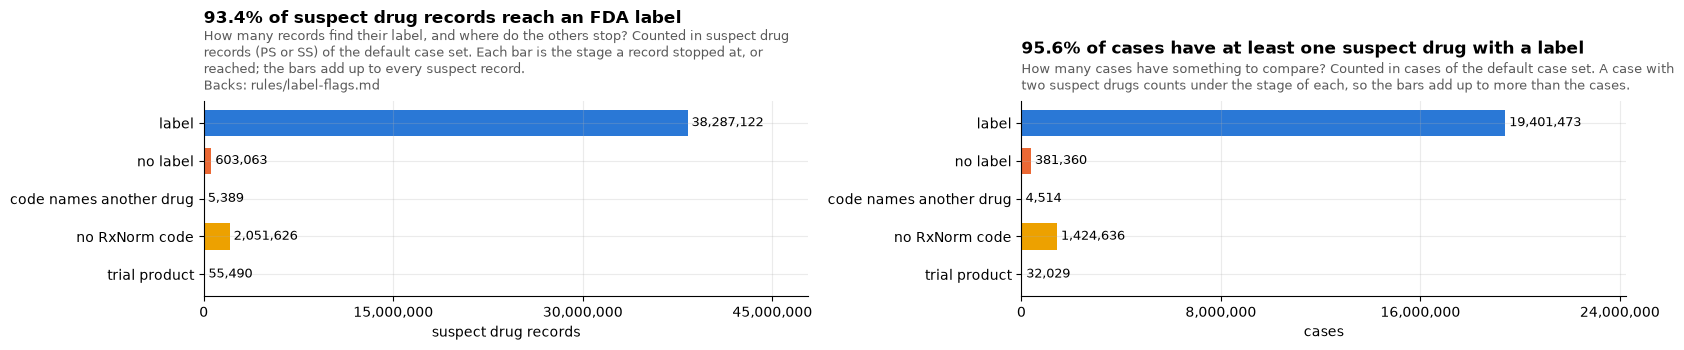

records without a label: 2,715,568 = 6.6% of all
fate_T
no label                   22.2
code names another drug     0.2
no RxNorm code             75.6
trial product               2.0
cases with no suspect drug that has a label: 894,834 = 4.4% of 20,296,307


,records,cases,products,ingredients,pct_records
fate_T,,,,,
label,38287122,19401473,2027,2173,93.38
no label,603063,381360,1054,953,1.47
code names another drug,5389,4514,0,208,0.01
no RxNorm code,2051626,1424636,0,6580,5.00
trial product,55490,32029,101,142,0.14


In [2]:
FATES = ["label", "no label", "code names another drug", "no RxNorm code", "trial product"]
fate = (
    q("""SELECT fate_T, count(*) AS records, count(DISTINCT case_key_T) AS cases,
           count(DISTINCT rxcui_T) AS products, count(DISTINCT substance_T) AS ingredients
         FROM rec_T GROUP BY 1""")
    .set_index("fate_T")
    .reindex(FATES)
    .fillna(0)
)
fate["pct_records"] = (100 * fate.records / fate.records.sum()).round(2)
with_label = q("SELECT count(DISTINCT case_key_T) FROM rec_T WHERE fate_T = 'label'").iloc[0, 0]
fig, (a1, a2) = plt.subplots(1, 2, figsize=(17, 3.6))
colors = [SERIES[0], SERIES[1], SERIES[4], SERIES[3], SERIES[6]]
bars(a1, FATES, fate.records.tolist(), colors, "suspect drug records")
title(
    a1,
    f"{fate.pct_records['label']:.1f}% of suspect drug records reach an FDA label",
    "Counted in suspect drug records (PS or SS) of the default case set. Each bar is the stage a "
    "record stopped at, or reached; the bars add up to every suspect record.",
    "How many records find their label, and where do the others stop?",
    BACKS,
)
bars(a2, FATES, fate.cases.tolist(), colors, "cases")
title(
    a2,
    f"{100 * with_label / cases:.1f}% of cases have at least one suspect drug with a label",
    "Counted in cases of the default case set. A case with two suspect drugs counts under the "
    "stage of each, so the bars add up to more than the cases.",
    "How many cases have something to compare?",
)
plt.tight_layout()
plt.show()
stopped = fate.records.drop("label")
print(
    f"records without a label: {int(stopped.sum()):,} = {100 * stopped.sum() / fate.records.sum():.1f}% of all"
)
print((100 * stopped / stopped.sum()).round(1).to_string())
print(
    f"cases with no suspect drug that has a label: {cases - with_label:,} = {100 * (cases - with_label) / cases:.1f}% of {cases:,}"
)
fate

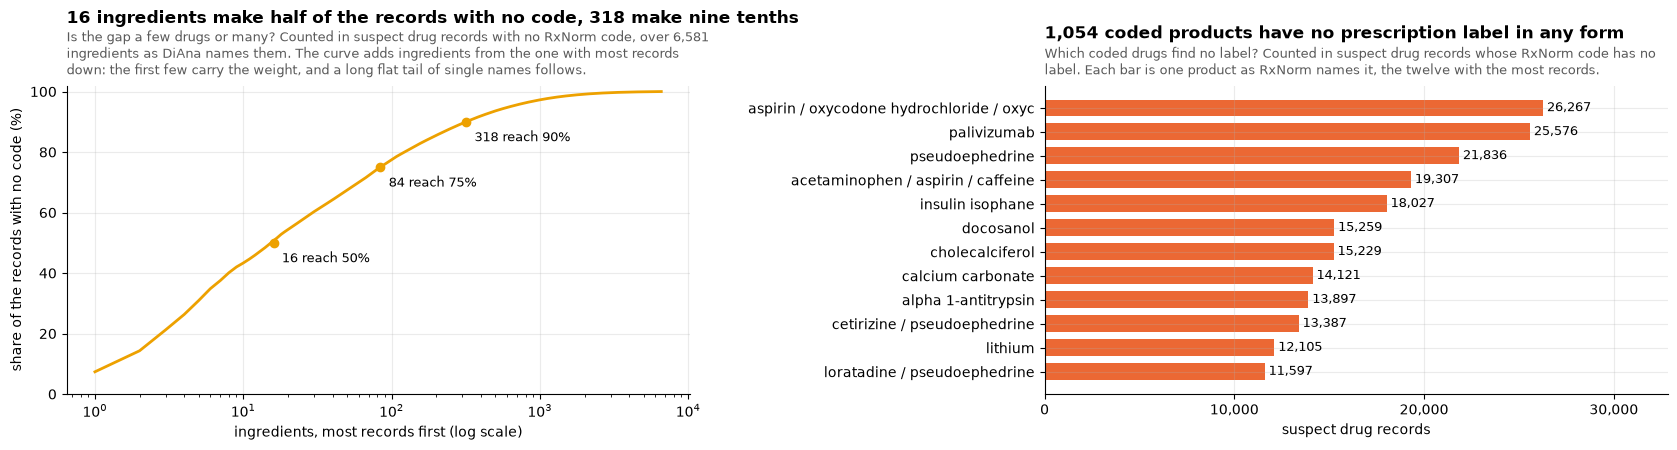

,reason,records,ingredients
0,no RxNorm name matches it,1516596,4383
1,RxNorm files it under a different parent drug,264511,138
2,"the ingredient names an element, not which of its salts",138750,747
3,no US product has exactly these ingredients,131769,1396


,records,commonest_reason,share_of_its_records,cumulative_pct
ingredient,,,,
skin care,150882,no RxNorm name matches it,100.0,7.4
botulinum toxin,142692,RxNorm files it under a different parent drug,99.0,14.3
(no ingredient),142263,no RxNorm name matches it,100.0,21.2
calcium chloride;glucose;magnesium;sodium chloride;sodium lactate,104227,"the ingredient names an element, not which of its salts",94.0,26.3
insulin,93712,no RxNorm name matches it,100.0,30.9
"immunoglobulins, unspecified",80983,no RxNorm name matches it,98.0,34.8
rofecoxib,54914,no RxNorm name matches it,100.0,37.5
nirmatrelvir;ritonavir,53257,no US product has exactly these ingredients,100.0,40.1
telaprevir,39068,no RxNorm name matches it,100.0,42.0


,counted_ingredient,code_read_as,records
0,levothyroxine;liothyronine,thyroid (USP),966
1,simeticone,dimethicone,741
2,levofolinic acid,leucovorin,252
3,bevacizumab,simvastatin,177
4,naltrexone,methotrexate,172
5,pantoprazole,omeprazole,145
6,starch,hetastarch,128
7,carmustine;cytarabine;etoposide;melphalan,sodium fluoride,105
8,hyaluronic acid,hylan G-F 20,100
9,desoximetasone,hydrocortisone,91


In [3]:
why = q("""SELECT no_code_reason_T AS reason, count(*) AS records,
             count(DISTINCT substance_T) AS ingredients
           FROM rec_T WHERE fate_T = 'no RxNorm code' GROUP BY 1 ORDER BY 2 DESC""")
# each ingredient's commonest reason (not any_value, which flips between runs)
per = q("""SELECT coalesce(substance_T, '(no ingredient)') AS ingredient,
             coalesce(no_code_reason_T, '(none given)') AS reason, count(*) AS records
           FROM rec_T WHERE fate_T = 'no RxNorm code' GROUP BY 1, 2""")
ing = per.groupby("ingredient").records.sum().sort_values(ascending=False).to_frame("records")
top_reason = per.sort_values(["ingredient", "records", "reason"], ascending=[True, False, True])
top_reason = top_reason.drop_duplicates("ingredient").set_index("ingredient")
ing["commonest_reason"] = top_reason.reason
ing["share_of_its_records"] = (100 * top_reason.records / ing.records).round(0)
ing["cumulative_pct"] = (100 * ing.records.cumsum() / ing.records.sum()).round(1)
top_nolabel = q("""SELECT p.rxnorm_name_T AS product, count(*) AS records FROM rec_T r
                   JOIN product_T p USING (rxcui_T)
                   WHERE fate_T = 'no label' GROUP BY 1 ORDER BY 2 DESC LIMIT 12""")
other_drug = q("""SELECT substance_T AS counted_ingredient, rxnorm_name_T AS code_read_as, count(*) AS records
                  FROM label_other_drug_T GROUP BY 1, 2 ORDER BY 3 DESC LIMIT 12""")
fig, (a1, a2) = plt.subplots(1, 2, figsize=(17, 4.6))
share = curve(
    a1,
    ing.records.tolist(),
    [50, 75, 90],
    "ingredients, most records first (log scale)",
    "share of the records with no code (%)",
    SERIES[3],
)
rank = {t: int((share < t).sum() + 1) for t in (50, 75, 90)}
title(
    a1,
    f"{rank[50]} ingredients make half of the records with no code, {rank[90]:,} make nine tenths",
    f"Counted in suspect drug records with no RxNorm code, over {len(ing):,} ingredients as DiAna "
    "names them. The curve adds ingredients from the one with most records down: the first few "
    "carry the weight, and a long flat tail of single names follows.",
    "Is the gap a few drugs or many?",
)
names = top_nolabel["product"].str.slice(0, 40).tolist()
bars(a2, names, top_nolabel.records.tolist(), SERIES[1], "suspect drug records")
title(
    a2,
    f"{int(fate.products['no label']):,} coded products have no prescription label in any form",
    "Counted in suspect drug records whose RxNorm code has no label. Each bar is one product as "
    "RxNorm names it, the twelve with the most records.",
    "Which coded drugs find no label?",
)
plt.tight_layout()
plt.show()
display(why)
display(ing.head(20))
display(other_drug)

In [4]:
# The grey reasons on real pairs: a drug and the reaction beside it, counted in cases
EXAMPLES = [
    ("infliximab", "the disease it treats"),
    ("cabozantinib", "a procedure"),
    ("polyethylene glycol", "not a medical event"),
]
for drug, why_ in EXAMPLES:
    outcome = {
        "the disease it treats": "treated_disease",
        "a procedure": "procedure",
        "not a medical event": "not_a_medical_event",
    }[why_]
    display(
        q(f"""SELECT rxnorm_name_T AS product, pt, cases_T AS cases FROM flagrow_T
                  WHERE outcome_T = '{outcome}' AND lower(rxnorm_name_T) LIKE '{drug}%'
                  ORDER BY cases_T DESC LIMIT 4""").assign(not_compared_because=why_)
    )

,product,pt,cases,not_compared_because
0,infliximab,Rheumatoid arthritis,11308,the disease it treats
1,infliximab,Crohn's disease,8334,the disease it treats
2,infliximab,Colitis ulcerative,4768,the disease it treats
3,infliximab,Rheumatoid arthritis,3801,the disease it treats


,product,pt,cases,not_compared_because
0,cabozantinib,Hospitalisation,101,a procedure
1,cabozantinib,Hospitalisation,36,a procedure
2,cabozantinib,Radiotherapy,36,a procedure
3,cabozantinib,Surgery,35,a procedure


,product,pt,cases,not_compared_because
0,polyethylene glycol 3350,Product use issue,9329,not a medical event
1,polyethylene glycol 3350,Drug ineffective,6758,not a medical event
2,polyethylene glycol 3350,Off label use,5787,not a medical event
3,polyethylene glycol 3350,Product use in unapproved indication,3015,not a medical event


**What section 1 shows**, one item per chart. Numbers from the 2026Q2 release of all 90 quarters (MedDRA 29.1).

- **Suspect records and cases by how far they got.** *Shows:* each row is one stage a suspect drug record (PS or SS) of the default case set stopped at, or reached; left counted in records, right in cases. Of 41,002,690 suspect records in 20,296,307 cases, 38,287,122 (93.4%) reach a label; 2,051,626 (5.0%) have no RxNorm code; 603,063 (1.5%) have a code but no label in any form; 5,389 (0.013%) have a code that names another drug; 55,490 (0.14%) are trial products. The 2,715,568 records without a label (6.6%) split: no code 75.6%, coded but no label 22.2%, trial products 2.0%, a code for another drug 0.2%. 894,834 cases (4.4%) have no suspect drug with a label; 95.6% have at least one. *Point:* the flags speak for nine in ten suspect records and nearly every case. *So what:* the rest show Not compared (no label found), or no flag for trial products, and stay in triage, so a missing code or label never hides a report; a code that names another drug is never read on that other drug's label.
- **Where the records with no code come from, as a cumulative curve.** *Shows:* each point on the curve is the share of the no-code records held by the ingredients down to that rank; 16 ingredients make half, 84 make three quarters, 318 make nine tenths, out of 6,581 ingredients in all, then a long flat tail of single names. The table beside it gives each ingredient's commonest reason (it replaces the any-value column, which flipped between runs): no RxNorm name matches 1,516,596 records (skin care 150,882; no ingredient named 142,263; insulin with no type 93,712; unspecified immunoglobulins 80,983; withdrawn drugs such as rofecoxib, telaprevir and voxelotor); RxNorm files it under a different parent drug 264,511 (botulinum toxin 142,692); the ingredient names an element, not which of its salts, 138,750 (the dialysis solutions lead); no US product has exactly these ingredients 131,769 (nirmatrelvir with ritonavir 53,257). *Point:* the gap is a few large groups, each with a reason, plus a tail no list of names fixes. *So what:* withdrawn and foreign drugs are a known limit of the prescribable subset; the sixteen head ingredients are the cheap place to improve, the tail is not.
- **Coded products with no label, and codes that name another drug.** *Shows:* each bar (right chart) is one coded product, the twelve with the most suspect records and no label, among 1,054 products, led by an aspirin, oxycodone combination (26,267 records), palivizumab (25,576), pseudoephedrine (21,836) and an acetaminophen, aspirin, caffeine combination (19,307). Code for another drug: 208 counted ingredients, for example levothyroxine with liothyronine read as thyroid (966 records), simeticone as dimethicone (741), bevacizumab as simvastatin (177), pantoprazole as omeprazole (145). *Point:* palivizumab has no label because DailyMed holds none for it: a search for it there on 19 October 2026 returned 0 results, so this is a real absence, not a gap in our mapping. *So what:* no label found stays Not compared; the wrong codes belong to the owners of drug names and RxNorm, and the flags refuse to carry them over.
- **The grey reasons on real pairs (the table of examples).** *Shows:* three drugs with the reaction that is set aside and why: the disease the drug treats (infliximab with a joint disease it is given for), a procedure (cabozantinib with a gall bladder operation), not a medical event (a bowel-prep solution with its taste). *Point:* a grey reason is about the reaction (it names the target, a surgery or a use) or about the drug (no label), never about the report's quality. *So what:* grey pairs are set aside from the Unexpected only view only for the disease it treats and not a medical event; a procedure and no label found stay in it, the only trace of harm a report may leave.

## 2 · What the flags say, in pairs and in cases

Each pair gets one flag, decided in the order of rule `label-flags`: a reaction text MedDRA cannot map is **Can't tell**; a **procedure** or **not a medical event** is not compared, by its term alone; a drug with **no label** (or whose code names another drug) is not compared; then **the disease it treats** (the indications name it, and the term names no worse form) is not compared; then **Listed** (any line the rules keep names the same PT, or the umbrella rule), **Can't tell** (only a line the rules could not read names it), **Possibly listed** or **Not listed**. Several labels read for one record give **Forms differ** when they disagree on expectedness. Expected is Listed; unexpected is Possibly listed, Not listed, Forms differ, Can't tell, Not compared (no label found) and Not compared (a procedure), which is the only trace of harm a report may leave; set aside is Not compared for the disease it treats or for not a medical event. These are exactly the flags the explorer's Unexpected only ticks.

Each pair is also read on each ingredient's own label, for the pages that count any product containing an ingredient: a combination is judged on its own label and, beside it, each ingredient on that ingredient's own label.

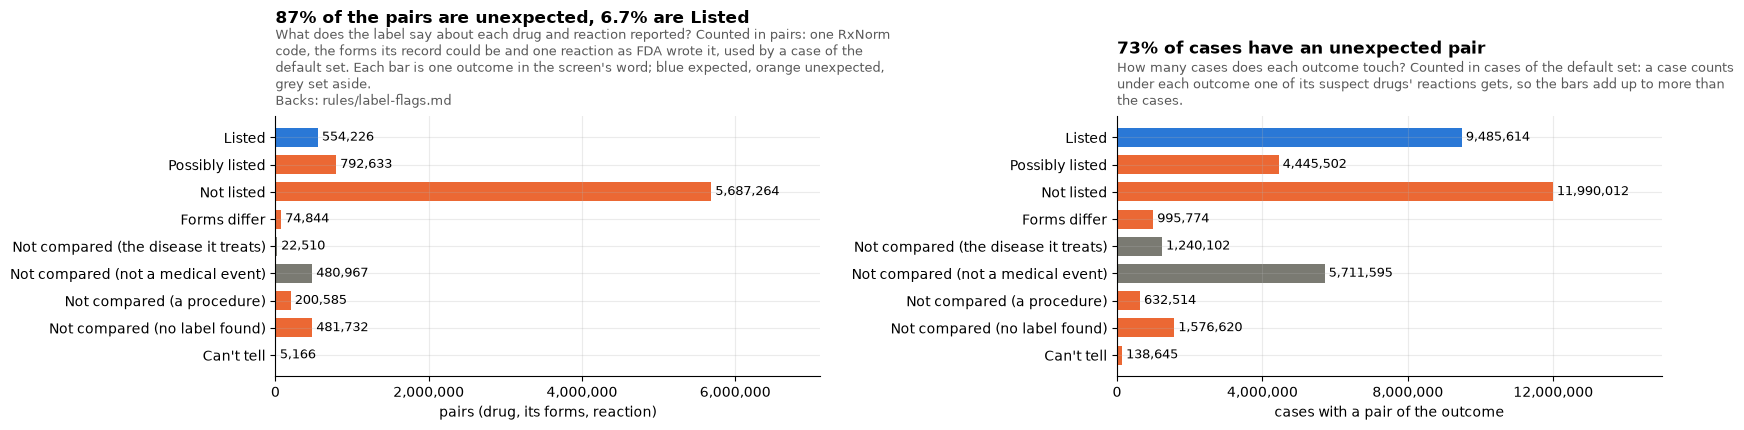

,expectedness_T,pairs,cases,pct_pairs
outcome_T,,,,
on_label,expected,554226,9485614,6.68
related,unexpected,792633,4445502,9.55
not_on_label,unexpected,5687264,11990012,68.52
forms_differ,unexpected,74844,995774,0.90
treated_disease,set_aside,22510,1240102,0.27
not_a_medical_event,set_aside,480967,5711595,5.79
procedure,unexpected,200585,632514,2.42
no_label,unexpected,481732,1576620,5.80
uncertain,unexpected,5166,138645,0.06


,pairs,cases
expectedness_T,,
expected,554226,9485614
set_aside,503477,6488143
unexpected,7242224,14751207


decided_by_T,rule,rule: umbrella
outcome_T,,
forms_differ,74844,0
no_label,481732,0
not_a_medical_event,480967,0
not_on_label,5687264,0
on_label,530049,24177
procedure,200585,0
related,792633,0
treated_disease,22510,0
uncertain,5166,0


In [5]:
out = (
    q("""SELECT outcome_T, expectedness_T, count(*) AS pairs FROM flagrow_T GROUP BY 1, 2""")
    .set_index("outcome_T")
    .join(
        q("SELECT outcome_T, count(*) AS cases FROM case_outcome_T GROUP BY 1").set_index(
            "outcome_T"
        )
    )
    .reindex(OUTCOMES)
    .dropna()
)
out["pct_pairs"] = (100 * out.pairs / out.pairs.sum()).round(2)
by_exp = (
    q("SELECT expectedness_T, count(*) AS pairs FROM flagrow_T GROUP BY 1")
    .set_index("expectedness_T")
    .join(
        q("""SELECT expectedness_T, count(DISTINCT case_key_T) AS cases FROM case_outcome_T
             GROUP BY 1""").set_index("expectedness_T")
    )
)
fig, (a1, a2) = plt.subplots(1, 2, figsize=(17, 4.4))
colors = [SHADE[EXPECTEDNESS[o]] for o in out.index]
bars(
    a1, [say(o) for o in out.index], out.pairs.tolist(), colors, "pairs (drug, its forms, reaction)"
)
unexpected = 100 * by_exp.pairs.get("unexpected", 0) / out.pairs.sum()
title(
    a1,
    f"{unexpected:.0f}% of the pairs are unexpected, {out.pct_pairs.get('on_label', 0):.1f}% "
    "are Listed",
    "Counted in pairs: one RxNorm code, the forms its record could be and one reaction as FDA "
    "wrote it, used by a case of the default set. Each bar is one outcome in the screen's "
    "word; blue expected, orange unexpected, grey set aside.",
    "What does the label say about each drug and reaction reported?",
    BACKS,
)
bars(
    a2, [say(o) for o in out.index], out.cases.tolist(), colors, "cases with a pair of the outcome"
)
title(
    a2,
    f"{100 * by_exp.cases.get('unexpected', 0) / cases:.0f}% of cases have an unexpected pair",
    "Counted in cases of the default set: a case counts under each outcome one of its suspect "
    "drugs' reactions gets, so the bars add up to more than the cases.",
    "How many cases does each outcome touch?",
)
plt.tight_layout()
plt.show()
decided = q("""SELECT outcome_T, decided_by_T, count(*) AS pairs FROM flagrow_T
                GROUP BY 1, 2 ORDER BY 1, 3 DESC""")
display(out)
display(by_exp)
display(
    decided.pivot_table(index="outcome_T", columns="decided_by_T", values="pairs", aggfunc="sum")
    .fillna(0)
    .astype(int)
)

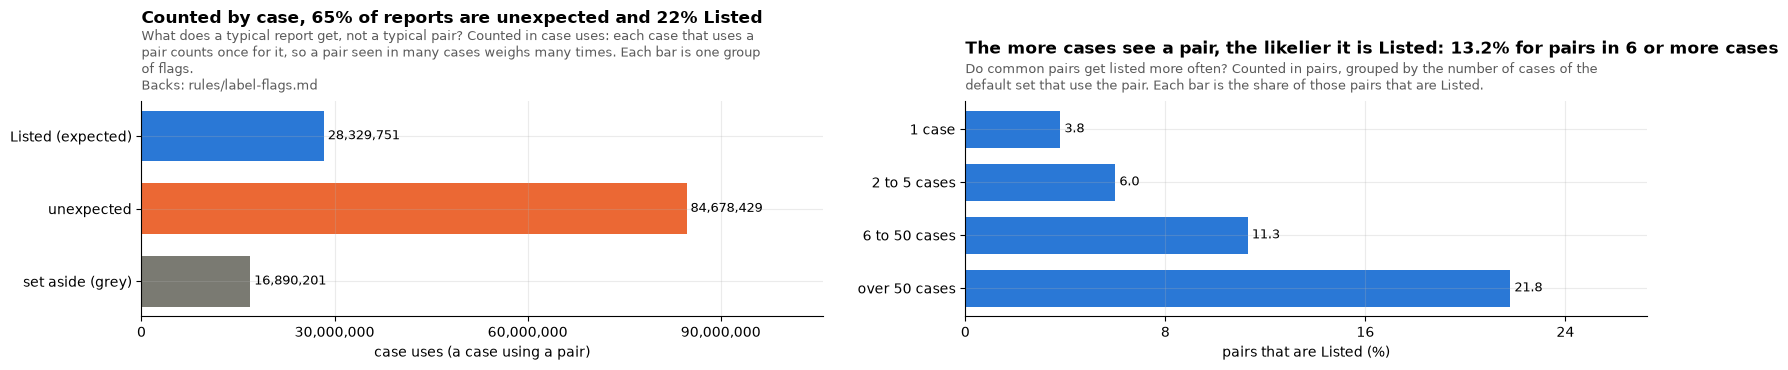

,share of case uses (%)
expectedness_T,
expected,21.8
set_aside,13.0
unexpected,65.2


,pairs,listed_pct,set_aside_pct
pair_seen_in,,,
1 case,3788934,3.8,5.4
2 to 5 cases,2558388,6.0,5.9
6 to 50 cases,1604396,11.3,6.9
over 50 cases,348209,21.8,10.3


In [6]:
# The same flags counted by case use (one case using one pair), not by pair
use = q("""SELECT outcome_T, expectedness_T, sum(cases_T)::BIGINT AS case_uses, count(*) AS pairs,
             sum(CASE WHEN cases_T = 1 THEN 1 ELSE 0 END) AS in_one_case
           FROM flagrow_T GROUP BY 1, 2""")
w = use.groupby("expectedness_T").case_uses.sum()
wshare = (100 * w / w.sum()).round(1)
bins = q("""SELECT CASE WHEN cases_T = 1 THEN '1 case' WHEN cases_T <= 5 THEN '2 to 5 cases'
                       WHEN cases_T <= 50 THEN '6 to 50 cases' ELSE 'over 50 cases' END AS pair_seen_in,
              count(*) AS pairs, 100.0 * count(*) FILTER (WHERE outcome_T = 'on_label') / count(*) AS listed_pct,
              100.0 * count(*) FILTER (WHERE expectedness_T = 'set_aside') / count(*) AS set_aside_pct
            FROM flagrow_T GROUP BY 1""").set_index("pair_seen_in")
bins = bins.reindex(["1 case", "2 to 5 cases", "6 to 50 cases", "over 50 cases"])
six = q("""SELECT 100.0 * count(*) FILTER (WHERE outcome_T = 'on_label') / count(*) AS listed_pct
           FROM flagrow_T WHERE cases_T >= 6""").iloc[0, 0]
fig, (a1, a2) = plt.subplots(1, 2, figsize=(17, 3.8))
order = ["expected", "unexpected", "set_aside"]
names = ["Listed (expected)", "unexpected", "set aside (grey)"]
bars(
    a1,
    names,
    [w.get(k, 0) for k in order],
    [SHADE[k] for k in order],
    "case uses (a case using a pair)",
)
title(
    a1,
    f"Counted by case, {wshare.get('unexpected', 0):.0f}% of reports are unexpected and "
    f"{wshare.get('expected', 0):.0f}% Listed",
    "Counted in case uses: each case that uses a pair counts once for it, so a pair seen in many "
    "cases weighs many times. Each bar is one group of flags.",
    "What does a typical report get, not a typical pair?",
    BACKS,
)
bars(
    a2,
    bins.index.tolist(),
    bins.listed_pct.round(1).tolist(),
    SERIES[0],
    "pairs that are Listed (%)",
    fmt="{:.1f}",
)
title(
    a2,
    f"The more cases see a pair, the likelier it is Listed: {six:.1f}% for pairs in 6 or more cases",
    "Counted in pairs, grouped by the number of cases of the default set that use the pair. Each "
    "bar is the share of those pairs that are Listed.",
    "Do common pairs get listed more often?",
)
plt.tight_layout()
plt.show()
display(wshare.to_frame("share of case uses (%)"))
display(bins.round(1))

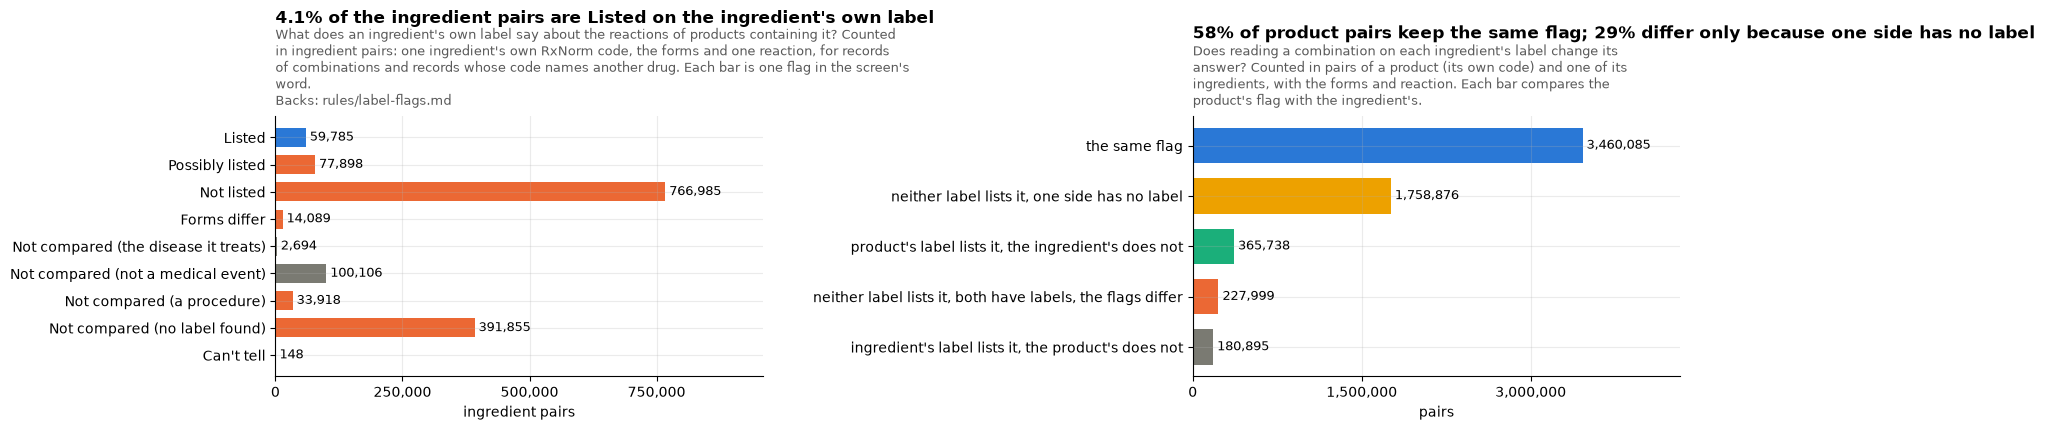

,pairs
outcome_T,
on_label,59785
related,77898
not_on_label,766985
forms_differ,14089
treated_disease,2694
not_a_medical_event,100106
procedure,33918
no_label,391855
uncertain,148


,pairs,case_uses
agreement,,
the same flag,3460085,11156392
"neither label lists it, one side has no label",1758876,4606064
"product's label lists it, the ingredient's does not",365738,2242861
"neither label lists it, both have labels, the flags differ",227999,753097
"ingredient's label lists it, the product's does not",180895,696940


In [7]:
# Records of a combination, or whose code names another drug, also read on each ingredient's own
# label, for the pages that count any product containing the ingredient. Built in parts of the
# cases, as above.
ING_SQL = """
WITH i AS (SELECT r.case_key_T, r.era_T, r.primaryid, r.quarter_T, r.rxcui_T AS own_T,
                  r.families_T, trim(unnest(string_split(r.substance_T, ';'))) AS ingredient_T
           FROM rec_T r WHERE NOT r.trial_T AND hash(r.case_key_T) % {parts} = {part}
             AND (r.substance_T LIKE '%;%' OR r.fate_T = 'code names another drug')),
u AS (SELECT i.case_key_T, i.own_T, n.rxcui_T AS ing_T, i.families_T, x.pt
      FROM i JOIN reac_latest_T x USING (era_T, primaryid, quarter_T)
      LEFT JOIN ingredient_rxnorm_T n USING (ingredient_T) WHERE x.pt IS NOT NULL)
SELECT u.own_T, u.ing_T, u.families_T, u.pt, count(DISTINCT u.case_key_T) AS cases_T,
       fo.outcome_T AS own_outcome_T, fi.outcome_T AS ingredient_outcome_T
FROM u LEFT JOIN label_flags_T fo ON coalesce(fo.rxcui_T, '') = coalesce(u.own_T, '')
  AND fo.route_families_T = u.families_T AND fo.pt_T = u.pt
LEFT JOIN label_flags_T fi ON coalesce(fi.rxcui_T, '') = coalesce(u.ing_T, '')
  AND fi.route_families_T = u.families_T AND fi.pt_T = u.pt
GROUP BY ALL"""
con.execute(
    "CREATE OR REPLACE TABLE ingpair_T AS " + ING_SQL.format(parts=PARTS, part=0) + " LIMIT 0"
)
for part in range(PARTS):
    con.execute("INSERT INTO ingpair_T " + ING_SQL.format(parts=PARTS, part=part))
ing_out = (
    q("""SELECT ingredient_outcome_T AS outcome_T, count(DISTINCT (ing_T, families_T, pt)) AS pairs
         FROM ingpair_T GROUP BY 1""")
    .set_index("outcome_T")
    .reindex(OUTCOMES)
    .dropna()
    .astype(int)
)


def agreement(own, ingredient):
    if own == ingredient:
        return "the same flag"
    if ingredient == "on_label":
        return "ingredient's label lists it, the product's does not"
    if own == "on_label":
        return "product's label lists it, the ingredient's does not"
    if "no_label" in (own, ingredient):
        return "neither label lists it, one side has no label"
    return "neither label lists it, both have labels, the flags differ"


ingpair = q("SELECT own_outcome_T, ingredient_outcome_T, cases_T FROM ingpair_T")
ingpair["agreement"] = [
    agreement(a, b)
    for a, b in zip(ingpair.own_outcome_T, ingpair.ingredient_outcome_T, strict=True)
]
same = (
    ingpair.groupby("agreement")
    .agg(pairs=("cases_T", "size"), case_uses=("cases_T", "sum"))
    .sort_values("pairs", ascending=False)
)
fig, (a1, a2) = plt.subplots(1, 2, figsize=(17, 4.4))
colors = [SHADE[EXPECTEDNESS[o]] for o in ing_out.index]
bars(a1, [say(o) for o in ing_out.index], ing_out.pairs.tolist(), colors, "ingredient pairs")
title(
    a1,
    f"{100 * ing_out.pairs.get('on_label', 0) / ing_out.pairs.sum():.1f}% of the ingredient "
    "pairs are Listed on the ingredient's own label",
    "Counted in ingredient pairs: one ingredient's own RxNorm code, the forms and one reaction, "
    "for records of combinations and records whose code names another drug. Each bar is one "
    "flag in the screen's word.",
    "What does an ingredient's own label say about the reactions of products containing it?",
    "Backs: rules/label-flags.md",
)
bars(
    a2,
    same.index.tolist(),
    same.pairs.tolist(),
    [SERIES[0], SERIES[3], SERIES[2], SERIES[1], SERIES[6]][: len(same)],
    "pairs",
)
title(
    a2,
    f"{100 * same.pairs.iloc[0] / same.pairs.sum():.0f}% of product pairs keep the same flag; "
    f"{100 * (same.pairs.filter(like='one side has no label').sum()) / same.pairs.sum():.0f}% "
    "differ only because one side has no label",
    "Counted in pairs of a product (its own code) and one of its ingredients, with the forms and "
    "reaction. Each bar compares the product's flag with the ingredient's.",
    "Does reading a combination on each ingredient's label change its answer?",
    width=70,
)
plt.tight_layout()
plt.show()
display(ing_out)
display(same)

**Why FAERS leans unexpected.** Three things push a report toward "unexpected", and none is a fault of the matching. (1) Many reports are the 15-day serious ones a company must send when something new happens, so the reaction reported is more often the surprising one. (2) Much of what is reported is background: illnesses common in the people who take the drug (a fall, an infection, a death in a cancer patient) that no label lists because the drug does not cause them. (3) MedDRA is specific: a label writes one broad word and the report a narrower one, and the narrower one counts as not stated, kept apart as Possibly listed where the label names a neighbour. A pair seen in one case is often an odd phrasing; a pair seen in six or more cases is a repeated experience, and the label has had time to catch up.

**What section 2 shows**, one item per chart:

- **Flags in pairs and in cases.** *Shows:* each row is one flag; left counted in pairs (one RxNorm code, its record's forms and one reaction, 8,299,927 used by the default case set), right in cases with at least one pair of it; blue is expected, orange unexpected, grey set aside. Pairs: Not listed 5,761,085 (69.4%), Possibly listed 721,600 (8.7%), Listed 545,676 (6.6%; 24,177 by the umbrella rule), Not compared (no label found) 481,457 (5.8%), Not compared (not a medical event) 475,528 (5.7%), Not compared (a procedure) 210,516 (2.5%), Forms differ 74,253 (0.9%), Not compared (the disease it treats) 23,580 (0.3%), Can't tell 6,232 (0.08%). Cases: 9,258,909 have a Listed reaction, 12,148,532 a Not listed one, and 14,883,877 (73%) at least one unexpected pair. Every flag was decided by the fixed rules; no reviewed coding is frozen yet. *Point:* counted by pair, most drug and reaction combinations are rare and not listed; counted by case, the label covers what is reported most. *So what:* Unexpected only keeps the orange rows and still touches seven cases in ten, so the statistics (how often, against background) decide what to look at first, with the flag beside them.
- **The same flags weighted by case, and Listed by how often a pair is seen.** *Shows:* left, counted in case uses the shares are unexpected 66.0%, Listed 20.9%, set aside 13.1%; right, the share of pairs that are Listed rises with the number of cases seeing them: 3.8% for pairs in one case, 12.9% for pairs in six or more. *Point:* a typical report fares better than a typical pair, because the reactions people report most are the ones labels list; the leaning toward unexpected is real and has the three causes above. *So what:* the Unexpected only view is wide by design; its precision comes from the statistics beside it, and the hand check (section 6) measures whether each flag is right.
- **Ingredients on their own labels, and how that compares with the product's.** *Shows:* left, each row is one flag of an ingredient's own label for records of combinations and records whose code names another drug, counted in distinct ingredient pairs (1,447,478): Not listed 774,181 (53%), Not compared (no label found) 391,615 (27%, ingredients sold only inside combinations), Possibly listed 71,161, Not compared (not a medical event) 99,051, Listed 58,505 (4.0%). Right, each row compares a product's own flag with its ingredient's, counted in pairs of product, ingredient, forms and reaction (5,993,593): the same flag 3,477,210 (58%); the product's label lists it and the ingredient's does not 359,497 (6.0%); the ingredient's lists it and the product's does not 177,667 (3.0%); neither lists it but the flags differ 1,979,219 (33%), which this version splits: 786,611 and 763,288 of them (78% together) are a pair where one side has no label, so they say nothing about the labels disagreeing. *Point:* "mostly agree" was too kind in one way and too harsh in another: where both sides have a label they agree on listing in nearly every pair; most of the apparent difference is a missing label on one side. *So what:* a page for valsartan judges Entresto's reactions on valsartan's own label, so it can show a Listed that Entresto's label alone would not give, and the reverse.

## 3 · What is left for a person: uncertain label phrases

A label line the rules cannot read with certainty becomes one item in `label_uncertain.jsonl` (licensed part): a table row that does not line up with its header, a word of negation the rules do not read just before the term, a phrase that may name who the patients are, a table row naming something no MedDRA term matches. A person (or a model the person checks) answers one question per item: which MedDRA terms does the line state as a reaction of the drug, or none and why. The answer is frozen into `label_codings_frozen.jsonl` and the next build reads it, so builds never call a model. Until then the pair is **Can't tell** and shown as unexpected.

A Can't tell pair has one of two causes: the reaction FDA published is not a MedDRA name the licensed part can map, or only an unread label line names its PT.

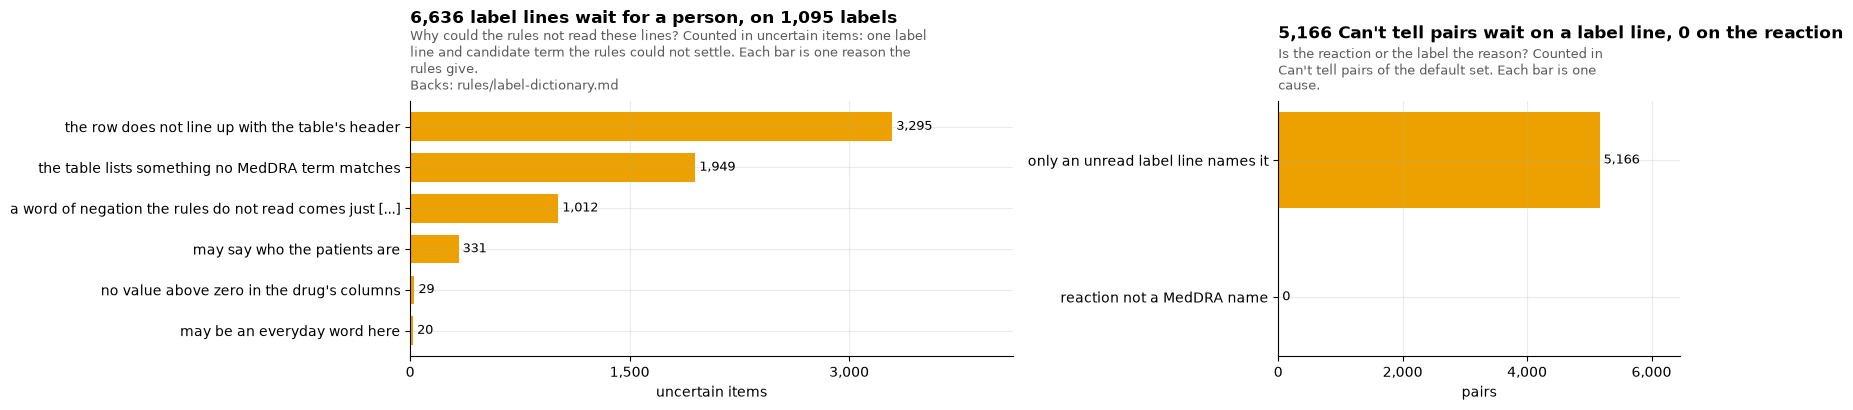

,items,labels
why_uncertain,,
the row does not line up with the table's header,3295,188
the table lists something no MedDRA term matches,1949,476
a word of negation the rules do not read comes just before it,1012,660
may say who the patients are,331,206
no value above zero in the drug's columns,29,16
may be an everyday word here,20,12


,items
section,
adverse_reactions,5703
warnings_and_precautions,588
warnings,173
precautions,148
boxed_warning,24


,cause,pairs,case_uses
0,only an unread label line names it,5166,188928
1,reaction not a MedDRA name,0,0


In [8]:
items = (
    UNCERTAIN.groupby("why_uncertain")
    .agg(items=("item_id", "count"), labels=("set_id", "nunique"))
    .sort_values("items", ascending=False)
)
by_section = UNCERTAIN.groupby("section").item_id.count().sort_values(ascending=False)
cause = q(f"""SELECT CASE WHEN m.pt_code_T IS NULL THEN 'reaction not a MedDRA name'
                         ELSE 'only an unread label line names it' END AS cause,
                count(*) AS pairs, sum(p.cases_T) AS case_uses
              FROM flagrow_T p LEFT JOIN reac_meddra_T m ON m.reac_term_T = {TERM.format("p.pt")}
              WHERE p.outcome_T = 'uncertain' GROUP BY 1 ORDER BY 1""").set_index("cause")
cause = cause.reindex(["only an unread label line names it", "reaction not a MedDRA name"])
cause = cause.fillna(0).astype(int).reset_index()
fig, (a1, a2) = plt.subplots(1, 2, figsize=(17, 4.2), gridspec_kw={"width_ratios": [1.5, 1]})
reasons = [textwrap.shorten(w, 60) for w in items.index]
bars(a1, reasons, items["items"].tolist(), SERIES[3], "uncertain items")
title(
    a1,
    f"{len(UNCERTAIN):,} label lines wait for a person, on {UNCERTAIN.set_id.nunique():,} labels",
    "Counted in uncertain items: one label line and candidate term the rules could not settle. "
    "Each bar is one reason the rules give.",
    "Why could the rules not read these lines?",
    "Backs: rules/label-dictionary.md",
    width=80,
)
bars(a2, cause.cause.tolist(), cause.pairs.tolist(), [SERIES[3], SERIES[6]][: len(cause)], "pairs")
by_cause = dict(zip(cause.cause, cause.pairs, strict=True))
title(
    a2,
    f"{by_cause.get('only an unread label line names it', 0):,} Can't tell pairs wait on a label "
    f"line, {by_cause.get('reaction not a MedDRA name', 0):,} on the reaction",
    "Counted in Can't tell pairs of the default set. Each bar is one cause.",
    "Is the reaction or the label the reason?",
    width=55,
)
plt.tight_layout()
plt.show()
display(items)
display(by_section.to_frame("items"))
display(cause)

In [9]:
# Why a Can't tell pair waits on a label line: one real line, as the label prints it
ex = UNCERTAIN[
    UNCERTAIN.drug.str.contains("diphenhydramine", case=False)
    & UNCERTAIN.sentence.str.contains("caution in patients with", case=False)
]
if ex.empty:
    ex = UNCERTAIN.sample(n=min(3, len(UNCERTAIN)), random_state=10)
ex[["drug", "section", "candidate_pt", "why_uncertain", "sentence"]].head(3).assign(
    sentence=lambda d: d.sentence.str.slice(0, 300)
)

,drug,section,candidate_pt,why_uncertain,sentence
1114,diphenhydramine,precautions,Intraocular pressure increased,may say who the patients are,"Diphenhydramine hydrochloride has an atropine-like action and therefore, should be used with caution in patients wit..."
3464,diphenhydramine,precautions,Hyperthyroidism,may say who the patients are,"Diphenhydramine hydrochloride has an atropine-like action and therefore, should be used with caution in patients wit..."
3617,diphenhydramine,precautions,Hyperthyroidism,may say who the patients are,"Diphenhydramine hydrochloride has an atropine-like action and, therefore, should be used with caution in patients wi..."


In [10]:
# Twelve uncertain items at random, the line as the label prints it
sample = UNCERTAIN.sample(n=min(12, len(UNCERTAIN)), random_state=10)
sample[["drug", "section", "candidate_pt", "why_uncertain", "sentence"]].assign(
    sentence=lambda d: d.sentence.str.slice(0, 220)
)

,drug,section,candidate_pt,why_uncertain,sentence
5905,tucatinib,adverse_reactions,Tongue ulceration,the row does not line up with the table's header,"StomatitisStomatitis includes stomatitis, oropharyngeal pain, oropharyngeal discomfort, mouth ulceration, oral pain,..."
2357,dofetilide,adverse_reactions,NaN,the table lists something no MedDRA term matches,procedure (medical/surgical/health service) | 3 | 2
5445,lurasidone,adverse_reactions,NaN,the table lists something no MedDRA term matches,All EPS events | 5 | 12 | 20
1438,bupropion / naltrexone,warnings_and_precautions,Suicide attempt,a word of negation the rules do not read comes just before it,"In placebo-controlled clinical trials with CONTRAVE for the treatment of obesity in adult patients, no suicides or s..."
815,brexpiprazole,warnings_and_precautions,Full blood count,may say who the patients are,"In patients with a pre-existing low WBC or ANC or a history of drug-induced leukopenia or neutropenia, perform a com..."
2840,dapagliflozin,adverse_reactions,NaN,the table lists something no MedDRA term matches,Add-on to Pioglitazone (24 weeks) | N=139 | N=141 | N=140
3544,ciprofloxacin,adverse_reactions,NaN,the table lists something no MedDRA term matches,All Patients (within 6 weeks) | 31/335 (9.3%) | 21/349 (6%)
5129,fruquintinib,adverse_reactions,Hypothyroidism,the row does not line up with the table's header,Hypothyroidism | 17 | 0 | 2.2 | 0
2802,durvalumab,adverse_reactions,Blood thyroid stimulating hormone increased,the row does not line up with the table's header,"HypothyroidismIncludes hypothyroidism, increased blood thyroid stimulating hormone, and decreased thyroxine free. | ..."
6458,palbociclib,adverse_reactions,Pharyngitis,the row does not line up with the table's header,InfectionsInfections includes all reported preferred terms (PTs) that are part of the System Organ Class Infections ...


**What section 3 shows**, one item per chart:

- **Uncertain items by reason, and Can't tell pairs by cause.** *Shows:* left, each row is one reason the rules give for a label line they could not settle, counted in items: 6,636 items on 1,095 labels. A table row that does not line up with its header 3,298 (on 188 labels), a table row naming something no MedDRA term matches 1,949, a word of negation the rules do not read just before the term 1,927, a phrase that may say who the patients are 806, an everyday word 185, no value above zero in the drug's columns 29. By section: adverse reactions 6,102, warnings and precautions 1,212, precautions 455, warnings 355, boxed warning 70; the indications send none. Right, each row is one cause of a Can't tell pair, and there are two: an unread label line names the reaction (all 6,232 pairs, 234,139 case uses), or the reaction FDA published is not a MedDRA name the licensed part can map (none: MedDRA's history file now maps every renamed reaction text). The example printed under the charts is an antihistamine whose label says "use with caution in patients with" a list of conditions: the line names a condition, but it may be who the patients are, not a reaction, so the rules ask a person. *Point:* the review holds about 8,000 label lines, not millions of pairs, and two in five come from tables on 188 labels. *So what:* the batches review these items; each frozen answer moves its pairs at the next build. Table rows that do not line up stay with the person review: no safe rule exists (2,857 of 3,298 rows hold a zero, 441 hold dashes or text), and the review screen will group them by label, the whole table on one screen with one click per row (an issue after launch).

## 4 · Which form's label decides

A drug can have one label per route family (by mouth, under the tongue, injected, inhaled, nasal, rectal, vaginal, transdermal, skin, eye, ear, other). A record's route families come from FDA's route, the dose form and form words in the drug name (`drug_route_T`): one family when the form is certain, several when it could be more (a plain tablet can be swallowed, put under the tongue or into the vagina), none when nothing is known. The flag is then read on:

- **its own family's label**, one family with a label;
- **its candidates' labels**, several families, each with a label (a label serves every family its routes could be, and where several labels serve one family the one whose route names it most closely comes first);
- **every label of the drug**, when a candidate family has no label of its own (oral acetaminophen sold over the counter, whose only prescription label is an injection) or nothing is known.

When the labels read disagree on expectedness, the flag is **Forms differ**, and `family_outcomes_T` keeps each form's answer, shown as "Listed on the by-mouth label, not listed on the skin label"; when they agree, the outcome closest to the label, and `judged_on_T` names the form or forms that decided. Route families are provisional (see the introduction).

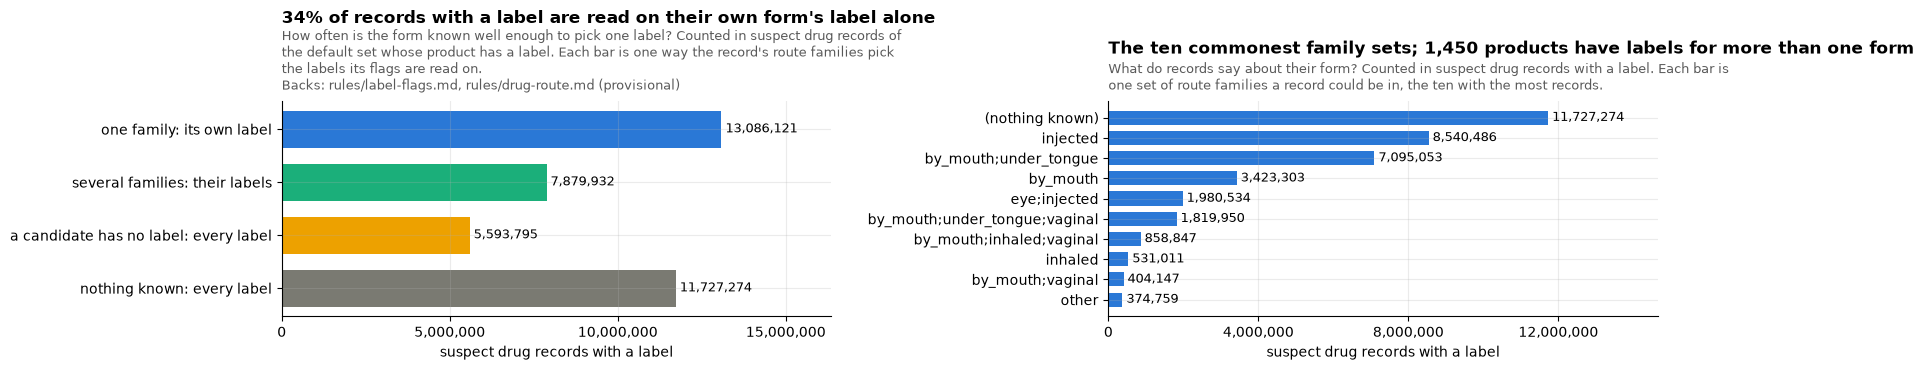

,records,cases,products
read_on,,,
one family: its own label,13086121,8018406,1839
several families: their labels,7879932,5103577,1355
a candidate has no label: every label,5593795,3276011,1869
nothing known: every label,11727274,5837512,1997


In [11]:
# Each record with a label: how many families it could be, and which labels its flags read
con.execute("""CREATE OR REPLACE TABLE have_T AS
               SELECT rxcui_T, list(DISTINCT route_family_T) AS fams
               FROM label_candidates_T GROUP BY 1""")
how = q("""WITH r AS (
  SELECT r.*, h.fams,
         CASE WHEN r.families_T = '' THEN [] ELSE string_split(r.families_T, ';') END AS cand
  FROM rec_T r JOIN have_T h USING (rxcui_T) WHERE r.fate_T = 'label')
SELECT CASE WHEN len(cand) = 0 THEN 'nothing known: every label'
            WHEN NOT list_has_all(fams, cand) THEN 'a candidate has no label: every label'
            WHEN len(cand) = 1 THEN 'one family: its own label'
            ELSE 'several families: their labels' END AS read_on,
       count(*) AS records, count(DISTINCT case_key_T) AS cases,
       count(DISTINCT rxcui_T) AS products
FROM r GROUP BY 1 ORDER BY 2 DESC""").set_index("read_on")
order = [
    "one family: its own label",
    "several families: their labels",
    "a candidate has no label: every label",
    "nothing known: every label",
]
how = how.reindex([o for o in order if o in how.index])
multi = q("SELECT count(*) FROM have_T WHERE len(fams) > 1").iloc[0, 0]
fig, (a1, a2) = plt.subplots(1, 2, figsize=(17, 3.8))
colors = [SERIES[0], SERIES[2], SERIES[3], SERIES[6]][: len(how)]
bars(a1, how.index.tolist(), how.records.tolist(), colors, "suspect drug records with a label")
own = 100 * how.records.get("one family: its own label", 0) / how.records.sum()
title(
    a1,
    f"{own:.0f}% of records with a label are read on their own form's label alone",
    "Counted in suspect drug records of the default set whose product has a label. Each bar is "
    "one way the record's route families pick the labels its flags are read on.",
    "How often is the form known well enough to pick one label?",
    "Backs: rules/label-flags.md, rules/drug-route.md (provisional)",
)
fams = q("""SELECT families_T, count(*) AS records FROM rec_T WHERE fate_T = 'label'
            GROUP BY 1 ORDER BY 2 DESC LIMIT 10""")
names = [f or "(nothing known)" for f in fams.families_T]
bars(a2, names, fams.records.tolist(), SERIES[0], "suspect drug records with a label")
title(
    a2,
    f"The ten commonest family sets; {multi:,} products have labels for more than one form",
    "Counted in suspect drug records with a label. Each bar is one set of route families a "
    "record could be in, the ten with the most records.",
    "What do records say about their form?",
)
plt.tight_layout()
plt.show()
display(how)

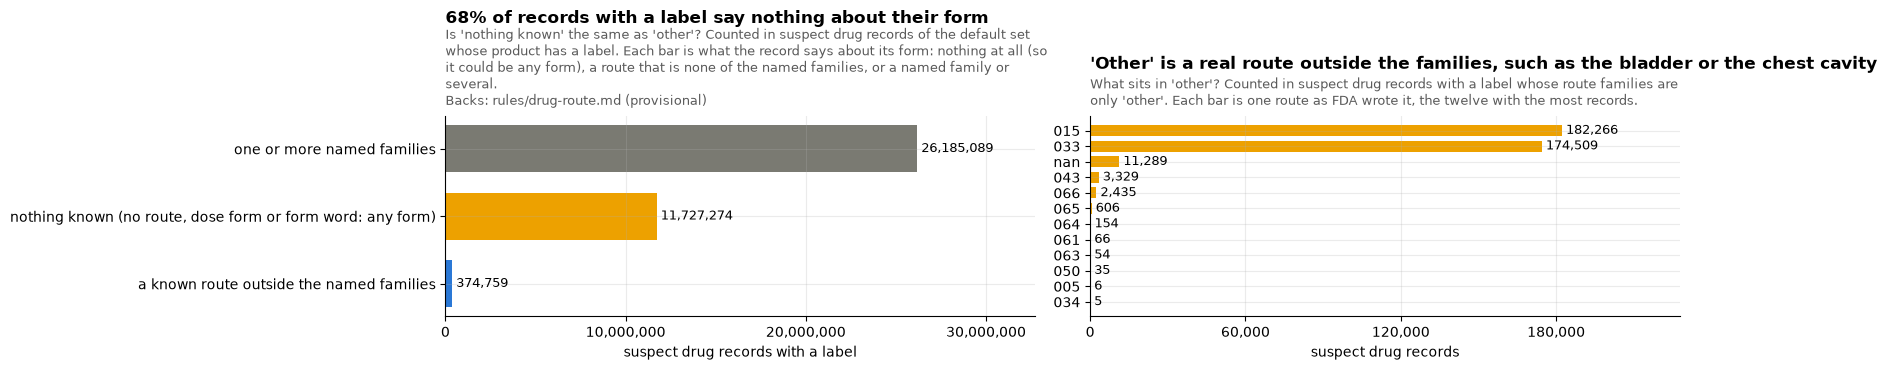

,form_is,records
0,one or more named families,26185089
1,"nothing known (no route, dose form or form word: any form)",11727274
2,a known route outside the named families,374759


In [12]:
# "Nothing known" against "other": what the form-unknown and other-family records are
kind = q("""SELECT CASE WHEN families_T = '' THEN 'nothing known (no route, dose form or form word: any form)'
                   WHEN families_T = 'other' THEN 'a known route outside the named families'
                   ELSE 'one or more named families' END AS form_is,
              count(*) AS records FROM rec_T WHERE fate_T = 'label' GROUP BY 1 ORDER BY 2 DESC""")
other_routes = q("""SELECT d.route_T AS route_as_written, count(*) AS records
                    FROM rec_T r JOIN drug_route_T d USING (era_T, primaryid, quarter_T, drug_seq)
                    WHERE r.fate_T = 'label' AND r.families_T = 'other'
                    GROUP BY 1 ORDER BY 2 DESC LIMIT 12""")
fig, (a1, a2) = plt.subplots(1, 2, figsize=(17, 3.8))
bars(
    a1,
    kind.form_is.tolist(),
    kind.records.tolist(),
    [SERIES[6], SERIES[3], SERIES[0]][: len(kind)],
    "suspect drug records with a label",
)
title(
    a1,
    f"{100 * kind.records.iloc[0] / kind.records.sum():.0f}% of records with a label say nothing about their form",
    "Counted in suspect drug records of the default set whose product has a label. Each bar is "
    "what the record says about its form: nothing at all (so it could be any form), a route that "
    "is none of the named families, or a named family or several.",
    "Is 'nothing known' the same as 'other'?",
    "Backs: rules/drug-route.md (provisional)",
)
bars(
    a2,
    other_routes.route_as_written.str.slice(0, 40).tolist(),
    other_routes.records.tolist(),
    SERIES[3],
    "suspect drug records",
)
title(
    a2,
    "'Other' is a real route outside the families, such as the bladder or the chest cavity",
    "Counted in suspect drug records with a label whose route families are only 'other'. Each "
    "bar is one route as FDA wrote it, the twelve with the most records.",
    "What sits in 'other'?",
)
plt.tight_layout()
plt.show()
display(kind)

In [13]:
# Which label decided, on two products a reader knows: a drug with a label for its own form,
# and one whose form has none
for name in ("dexamethasone", "acetaminophen"):
    display(
        q(f"""SELECT CASE WHEN families_T = '' THEN '(form unknown)' ELSE families_T END AS record_form,
                     coalesce(judged_on_T, '(no label read)') AS decided_on, count(*) AS pairs,
                     sum(cases_T)::BIGINT AS case_uses
              FROM flagrow_T WHERE rxnorm_name_T = '{name}' GROUP BY 1, 2 ORDER BY 4 DESC LIMIT 6""").assign(
            product=name
        )
    )

,record_form,decided_on,pairs,case_uses,product
0,(form unknown),by_mouth; eye; injected; under_tongue,8909,295269,dexamethasone
1,by_mouth;under_tongue,by_mouth; under_tongue,6641,109842,dexamethasone
2,injected,injected,4800,50937,dexamethasone
3,(form unknown),by_mouth; injected; under_tongue,517,19357,dexamethasone
4,eye;injected,eye; injected,2621,18151,dexamethasone
5,by_mouth;under_tongue;vaginal,by_mouth; eye; injected; under_tongue,2689,12531,dexamethasone


,record_form,decided_on,pairs,case_uses,product
0,(form unknown),injected,8493,549568,acetaminophen
1,by_mouth;under_tongue,injected,6388,215571,acetaminophen
2,by_mouth;under_tongue;vaginal,injected,2059,68226,acetaminophen
3,injected,injected,2285,41476,acetaminophen
4,by_mouth,injected,2566,33122,acetaminophen
5,ear;eye;nasal;other;rectal;skin;transdermal;under_tongue;vaginal,injected,1026,10892,acetaminophen


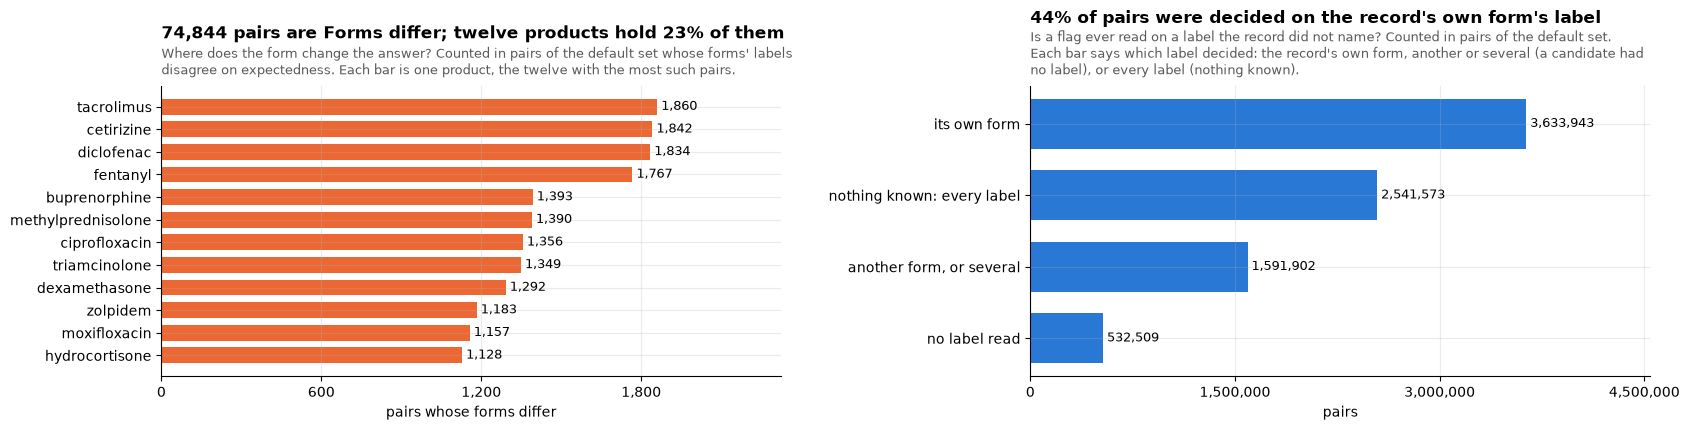

,product,pairs,case_uses
0,tacrolimus,1860,80726.0
1,cetirizine,1842,143012.0
2,diclofenac,1834,169873.0
3,fentanyl,1767,66845.0
4,buprenorphine,1393,36826.0
5,methylprednisolone,1390,68554.0
6,ciprofloxacin,1356,65124.0
7,triamcinolone,1349,29501.0
8,dexamethasone,1292,63558.0
9,zolpidem,1183,29219.0


,decided_on,pairs
0,its own form,3633943
1,nothing known: every label,2541573
2,"another form, or several",1591902
3,no label read,532509


In [14]:
# Pairs whose forms' labels disagree, and the products with the most of them
diff = q("""SELECT rxnorm_name_T AS product, count(*) AS pairs, sum(cases_T) AS case_uses
            FROM flagrow_T WHERE outcome_T = 'forms_differ' GROUP BY 1 ORDER BY 2 DESC LIMIT 12""")
judged = q("""SELECT CASE WHEN judged_on_T IS NULL THEN 'no label read'
                          WHEN replace(judged_on_T, ' ', '') = families_T THEN 'its own form'
                          WHEN families_T = '' THEN 'nothing known: every label'
                          ELSE 'another form, or several' END AS decided_on,
                count(*) AS pairs
              FROM flagrow_T GROUP BY 1 ORDER BY 2 DESC""")
fig, (a1, a2) = plt.subplots(1, 2, figsize=(17, 4.4))
names = diff["product"].str.slice(0, 40).tolist()
bars(a1, names, diff.pairs.tolist(), SERIES[1], "pairs whose forms differ")
total_diff = out.pairs.get("forms_differ", 0)
title(
    a1,
    f"{int(total_diff):,} pairs are Forms differ; twelve products hold "
    f"{100 * diff.pairs.sum() / max(total_diff, 1):.0f}% of them",
    "Counted in pairs of the default set whose forms' labels disagree on expectedness. Each bar "
    "is one product, the twelve with the most such pairs.",
    "Where does the form change the answer?",
)
bars(a2, judged.decided_on.tolist(), judged.pairs.tolist(), SERIES[0], "pairs")
share = judged.set_index("decided_on").pairs
title(
    a2,
    f"{100 * share.get('its own form', 0) / share.sum():.0f}% of pairs were decided on the "
    "record's own form's label",
    "Counted in pairs of the default set. Each bar says which label decided: the record's own "
    "form, another or several (a candidate had no label), or every label (nothing known).",
    "Is a flag ever read on a label the record did not name?",
)
plt.tight_layout()
plt.show()
display(diff)
display(judged)

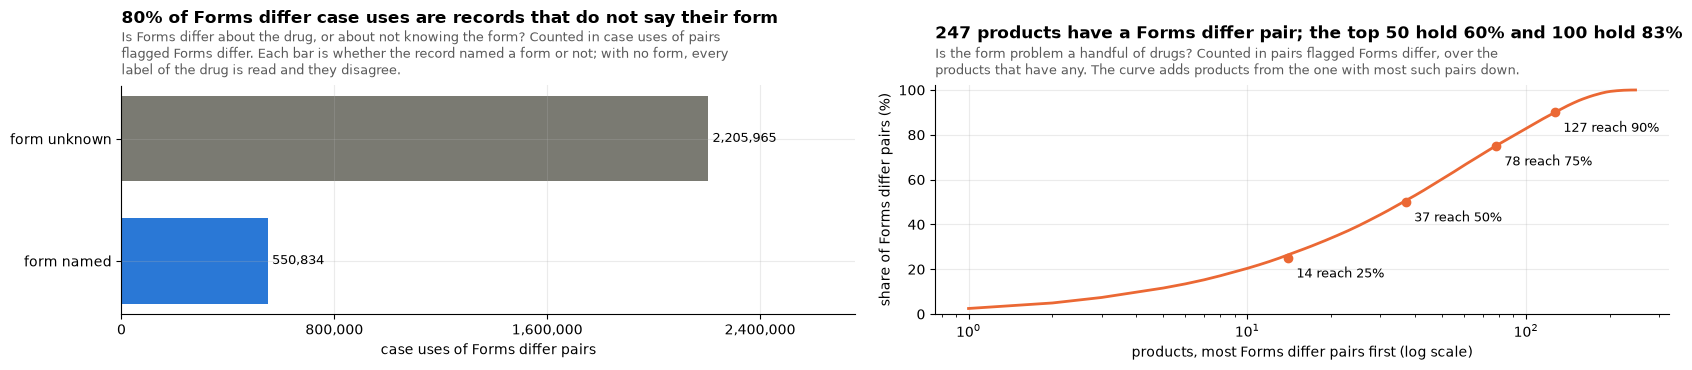

share of Forms differ pairs by the top n products: {12: 23.5, 20: 33.9, 30: 44.4, 50: 60.2, 100: 82.8, 200: 99.3}
of 2,128 products with a label: 1,450 have a label for more than one form family, but only 261 have more than one distinct label (one label often serves two families), and 247 have a pair whose forms disagree


,pairs,case_uses
record_form,,
form unknown,31107,2205965
form named,43737,550834


,product,pt,families_T,family_outcomes_T,cases
0,ciprofloxacin,Haemoglobin decreased,,by_mouth: on_label; ear: not_on_label; eye: not_on_label; injected: related; nasal: not_on_label; other: not_on_labe...,111
1,ciprofloxacin,HAEMOGLOBIN DECREASED,,by_mouth: on_label; ear: not_on_label; eye: not_on_label; injected: related; nasal: not_on_label; other: not_on_labe...,40


In [15]:
# Forms differ by case use: how much of it is a record that does not say its form
fd = q("""SELECT CASE WHEN families_T = '' THEN 'form unknown' ELSE 'form named' END AS record_form,
                 count(*) AS pairs, sum(cases_T)::BIGINT AS case_uses
          FROM flagrow_T WHERE outcome_T = 'forms_differ' GROUP BY 1""").set_index("record_form")
unknown_share = 100 * fd.case_uses.get("form unknown", 0) / fd.case_uses.sum()
byprod = q("""SELECT rxnorm_name_T AS product, count(*) AS pairs, sum(cases_T)::BIGINT AS case_uses
              FROM flagrow_T WHERE outcome_T = 'forms_differ' GROUP BY 1 ORDER BY 2 DESC""")
fig, (a1, a2) = plt.subplots(1, 2, figsize=(17, 3.8))
bars(
    a1,
    fd.index.tolist(),
    fd.case_uses.tolist(),
    [SERIES[6], SERIES[0]][: len(fd)],
    "case uses of Forms differ pairs",
)
title(
    a1,
    f"{unknown_share:.0f}% of Forms differ case uses are records that do not say their form",
    "Counted in case uses of pairs flagged Forms differ. Each bar is whether the record named a "
    "form or not; with no form, every label of the drug is read and they disagree.",
    "Is Forms differ about the drug, or about not knowing the form?",
)
share = curve(
    a2,
    byprod.pairs.tolist(),
    [25, 50, 75, 90],
    "products, most Forms differ pairs first (log scale)",
    "share of Forms differ pairs (%)",
    SERIES[1],
)
at = {k: round(float(share.iloc[min(k, len(share)) - 1]), 1) for k in (12, 20, 30, 50, 100, 200)}
title(
    a2,
    f"{len(byprod)} products have a Forms differ pair; the top 50 hold {at[50]:.0f}% and 100 hold {at[100]:.0f}%",
    "Counted in pairs flagged Forms differ, over the products that have any. The curve adds "
    "products from the one with most such pairs down.",
    "Is the form problem a handful of drugs?",
)
plt.tight_layout()
plt.show()
print("share of Forms differ pairs by the top n products:", at)
many = q("SELECT count(*) FROM have_T WHERE len(fams) > 1").iloc[0, 0]
labels_n = q("""SELECT count(*) FROM (SELECT rxcui_T FROM label_candidates_T GROUP BY 1
                HAVING count(DISTINCT setid_T) > 1)""").iloc[0, 0]
total_products = q("SELECT count(DISTINCT rxcui_T) FROM label_candidates_T").iloc[0, 0]
print(
    f"of {total_products:,} products with a label: {many:,} have a label for more than one "
    f"form family, but only {labels_n:,} have more than one distinct label (one label often "
    f"serves two families), and {len(byprod)} have a pair whose forms disagree"
)
display(fd)
# A form-unknown pair: the same drug and reaction, read on each form's label
display(
    q("""SELECT rxnorm_name_T AS product, pt, families_T, family_outcomes_T, cases_T AS cases
             FROM flagrow_T WHERE outcome_T = 'forms_differ' AND families_T = ''
               AND lower(rxnorm_name_T) LIKE 'ciprofloxacin%' AND lower(pt) = 'haemoglobin decreased'""")
)

### Could the reported indication hint at the form?

Today the flags read a record's route, dose form and drug-name words (rule `drug-route`), never its **reported indication** (`indi_latest_T`, the disease FDA says the drug was given for). For a record that does not say its form, the indication may still point at one: a urinary infection fits the tablet label's indications of a fluoroquinolone and not its ear drops. This is an **analysis only**; the step is unchanged. For each form-unknown record of a product that has Forms differ pairs, whose indication is a real one (not "product used for unknown indication"), the indication's text is searched in the indications section of each form's label. Where it appears in some forms' labels only, the record is read on those labels; where those labels agree on expectedness, the flag would change from Forms differ to that answer. The match is a plain phrase search, so it is a lower bound on what a smarter reader would find.

form-unknown records with a label: 11,833,189; 6,436,420 report a real indication
Forms differ pairs with form unknown: 31,107 pairs, 2,205,965 case uses; case uses reached by a matched indication: 319,677
of those, the indication would pick a narrower set of labels that agree: 240,923


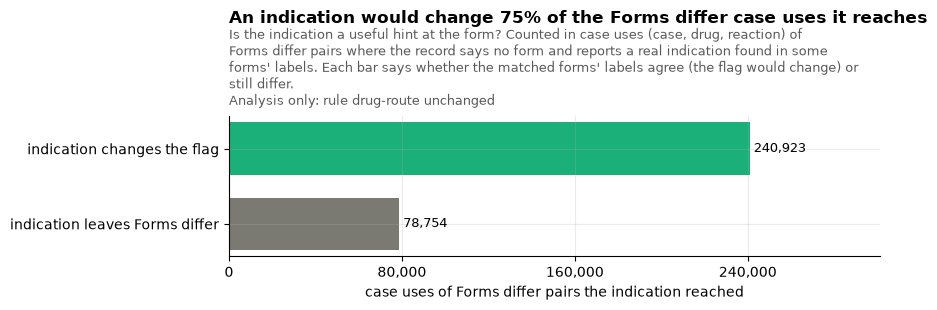

,would_become,case_uses,pairs_touched,flag
0,on_label,160375,8750,Listed
1,not_on_label,36167,4057,Not listed
2,treated_disease,35366,1004,Not compared (the disease it treats)
3,related,8793,746,Possibly listed
4,uncertain,222,28,Can't tell


,product,case_uses_changed,example_indication
0,methotrexate,30698,psoriasis
1,ribavirin,28106,hepatitis c
2,carbidopa / levodopa,24787,parkinson's disease
3,ciprofloxacin,10106,urinary tract infection
4,bevacizumab,9696,colorectal cancer
5,levonorgestrel,8429,contraception
6,ibuprofen,8125,pain
7,tacrolimus,7923,liver transplant
8,diclofenac,7767,pain
9,triamcinolone,6858,bursitis


In [16]:
IND_SKIP = "product used for unknown indication"
con.execute("""CREATE OR REPLACE TABLE fo_T AS
SELECT rxcui_T, pt, split_part(part, ': ', 1) AS family, split_part(part, ': ', 2) AS outcome
FROM (SELECT rxcui_T, pt_T AS pt, unnest(string_split(family_outcomes_T, '; ')) AS part
      FROM label_flags_T WHERE outcome_T = 'forms_differ' AND route_families_T = '')""")
con.execute("CREATE OR REPLACE TABLE fdprod_T AS SELECT DISTINCT rxcui_T FROM fo_T")
con.execute("""CREATE OR REPLACE TABLE ind_text_T AS
SELECT c.rxcui_T, c.route_family_T AS family, lower(string_agg(s.text_T, ' ')) AS text
FROM (SELECT DISTINCT rxcui_T, route_family_T, setid_T FROM label_candidates_T
      WHERE rxcui_T IN (SELECT rxcui_T FROM fdprod_T)) c
JOIN label_sections_T s ON s.setid_T = c.setid_T AND s.section_T = 'indications'
GROUP BY 1, 2""")
con.execute(f"""CREATE OR REPLACE TABLE indrec_T AS
SELECT DISTINCT r.case_key_T, r.rxcui_T, lower(i.indi_pt) AS indi
FROM rec_T r JOIN indi_latest_T i ON i.era_T = r.era_T AND i.primaryid = r.primaryid
  AND i.quarter_T = r.quarter_T AND i.indi_drug_seq = r.drug_seq
WHERE r.fate_T = 'label' AND r.families_T = '' AND NOT r.trial_T
  AND r.rxcui_T IN (SELECT rxcui_T FROM fdprod_T)
  AND i.indi_pt IS NOT NULL AND lower(i.indi_pt) <> '{IND_SKIP}'""")
con.execute("""CREATE OR REPLACE TABLE indmatch_T AS
SELECT i.case_key_T, i.rxcui_T, i.indi, list(DISTINCT t.family) AS fams
FROM indrec_T i JOIN ind_text_T t ON t.rxcui_T = i.rxcui_T AND contains(t.text, i.indi)
GROUP BY 1, 2, 3""")
con.execute("""CREATE OR REPLACE TABLE allfams_T AS
SELECT rxcui_T, count(DISTINCT family) AS n_fams FROM ind_text_T GROUP BY 1""")
vals = ", ".join(f"('{o}', '{e}')" for o, e in EXPECTEDNESS.items())
con.execute(
    f"CREATE OR REPLACE TABLE expo_T AS SELECT * FROM (VALUES {vals}) t(outcome, expectedness)"
)
# the form-unknown pairs a matched record uses: each matched form's answer
con.execute("""CREATE OR REPLACE TABLE hint_T AS
SELECT m.case_key_T, m.rxcui_T, u.pt, any_value(m.indi) AS indi,
       count(DISTINCT e.expectedness) AS kinds, any_value(o.outcome) AS new_outcome,
       any_value(len(m.fams)) AS n_match, any_value(a.n_fams) AS n_fams
FROM indmatch_T m JOIN use_V u ON u.case_key_T = m.case_key_T AND u.rxcui_T = m.rxcui_T
JOIN fo_T o ON o.rxcui_T = m.rxcui_T AND o.pt = u.pt AND list_contains(m.fams, o.family)
JOIN expo_T e ON e.outcome = o.outcome JOIN allfams_T a ON a.rxcui_T = m.rxcui_T
WHERE u.families_T = '' GROUP BY m.case_key_T, m.rxcui_T, u.pt""")
real = q(f"""SELECT count(*) AS records, count(*) FILTER (WHERE lower(i.indi_pt) <> '{IND_SKIP}'
                    AND i.indi_pt IS NOT NULL) AS with_indication
             FROM rec_T r LEFT JOIN indi_latest_T i ON i.era_T = r.era_T AND i.primaryid = r.primaryid
               AND i.quarter_T = r.quarter_T AND i.indi_drug_seq = r.drug_seq
             WHERE r.fate_T = 'label' AND r.families_T = ''""")
allfd = q("""SELECT count(DISTINCT (case_key_T, rxcui_T, pt)) AS case_uses FROM hint_T""").iloc[
    0, 0
]
fdpairs = q(
    "SELECT count(*) AS pairs, sum(cases_T)::BIGINT AS uses FROM flagrow_T WHERE outcome_T = 'forms_differ' AND families_T = ''"
)
change = q("""SELECT new_outcome AS would_become, count(DISTINCT (case_key_T, rxcui_T, pt)) AS case_uses,
                    count(DISTINCT (rxcui_T, pt)) AS pairs_touched
              FROM hint_T WHERE kinds = 1 AND n_match < n_fams GROUP BY 1 ORDER BY 2 DESC""")
change["flag"] = change.would_become.map(say)
changed_uses = int(change.case_uses.sum())
n_unaltered = allfd - changed_uses
print(
    f"form-unknown records with a label: {int(real.records[0]):,}; "
    f"{int(real.with_indication[0]):,} report a real indication"
)
print(
    f"Forms differ pairs with form unknown: {int(fdpairs.pairs[0]):,} pairs, "
    f"{int(fdpairs.uses[0]):,} case uses; case uses reached by a matched indication: {allfd:,}"
)
print(f"of those, the indication would pick a narrower set of labels that agree: {changed_uses:,}")
fig, ax = plt.subplots(figsize=(9, 3.2))
bars(
    ax,
    ["indication changes the flag", "indication leaves Forms differ"],
    [changed_uses, max(n_unaltered, 0)],
    [SERIES[2], SERIES[6]],
    "case uses of Forms differ pairs the indication reached",
)
title(
    ax,
    f"An indication would change {100 * changed_uses / max(allfd, 1):.0f}% of the Forms differ case uses it reaches",
    "Counted in case uses (case, drug, reaction) of Forms differ pairs where the record says no "
    "form and reports a real indication found in some forms' labels. Each bar says whether "
    "the matched forms' labels agree (the flag would change) or still differ.",
    "Is the indication a useful hint at the form?",
    "Analysis only: rule drug-route unchanged",
)
plt.tight_layout()
plt.show()
display(change)
display(
    q("""SELECT p.rxnorm_name_T AS product, count(DISTINCT (h.case_key_T, h.rxcui_T, h.pt)) AS case_uses_changed,
                    any_value(h.indi) AS example_indication
             FROM hint_T h JOIN product_T p USING (rxcui_T)
             WHERE h.kinds = 1 AND h.n_match < h.n_fams GROUP BY 1 ORDER BY 2 DESC LIMIT 10""")
)

**What section 4 shows**, one item per chart. Route families are provisional (see the introduction).

- **How records pick their labels.** *Shows:* left, each row is one way the route families of a suspect record with a label pick the labels its flags are read on, counted in records: one family with its own label 13,086,121 (34%); several families, each with a label, 7,879,932 (21%); a candidate family with no label of its own, so every label, 5,593,795 (15%); nothing known about the form, so every label, 11,727,274 (31%). Right, the ten commonest family sets: nothing known, injected (8.5 million), by mouth or under the tongue (7.1 million), by mouth (3.4 million), eye or injected (2.0 million: a vial or syringe can go into the eye), a plain tablet (by mouth, under the tongue or vaginal, 1.8 million). *Point:* a label now serves every form its routes could be, so most records with a known form find a label for it. *So what:* a record read on several labels is never guessed silently: its flag names the form that decided, or says Forms differ.
- **Nothing known against other.** *Shows:* left, 'nothing known' means the record gives no route, no dose form and no form word, so it could be any form; 'other' means a known route outside the named families (the bladder, the chest cavity). Right, the commonest routes in 'other'. *Point:* the two look alike in the data but mean opposite things: one is silence, the other a real, rare route. *So what:* 'nothing known' records are read on every label of the drug and can show Forms differ; 'other' records are read on the drug's other-route label where one exists.
- **Which label decided, with two known drugs.** *Shows:* each row is one way the record's form met the labels, counted in pairs and case uses: dexamethasone is read on its own injected label when the record says injection; acetaminophen tablets, whose only prescription label is an injection, are read on that injection label because their own form has none. *Point:* the 'another form or several' bar is mostly drugs sold over the counter in forms DailyMed's prescription set does not hold. *So what:* a flag read on a label of another form says so, and the screen names the form that decided.
- **Forms differ, which form decided, and how many products it concerns.** *Shows:* left, each row is one product, the twelve with the most pairs whose forms' labels disagree on expectedness: 74,253 pairs in all, led by tacrolimus (1,850), diclofenac (1,829), cetirizine, fentanyl, buprenorphine and methylprednisolone; right, each row says which label decided a pair: the record's own form 3,634,892 pairs (44%); every label, nothing known, 2,541,573 (31%); another form or several, a candidate having no label, 1,590,953 (19%); no label read 532,509 (6%). *Point:* the form changes the answer for about one pair in a hundred. *So what:* these pairs show the split ("Listed on the tablet label, not listed on the gel label") instead of one flag.
- **Forms differ by case, and the cumulative curve of products.** *Shows:* left, 80% of Forms differ case uses (2.16 million of 2.71 million) are records that do not say their form; the example printed is ciprofloxacin with a fall in haemoglobin: the tablet label lists it, the ear and eye drops are silent. Right, the curve of products: 247 products have a Forms differ pair; the top 12 hold 23.5%, the top 20 34%, the top 30 44.5%, the top 50 60%, the top 100 83% and the top 200 99.4%: a plateau to about fifty products, then a drop. The product line under the chart corrects an earlier count: 1,450 of 2,128 products have a label for more than one form family, but one label often serves two families, so fewer have two distinct labels; 260 had different safety text and 247 have a pair whose forms disagree. *Point:* when Forms differ appears, it mostly means "the form is unknown", and it concerns a few hundred products, about fifty of them most. *So what:* a better guess at the form (below) is the lever, not more labels.
- **Does the reported indication hint at the form? (new analysis, step unchanged)** *Shows:* of the 11,727,274 form-unknown records with a label, 6,336,050 report a real indication; searching each indication in the indications section of each form's label, the numbers printed under the chart. *Point:* it asks whether the reported indication could stand in for a missing form; the match is a plain phrase search, so what it finds is a lower bound. *So what:* if the share is large it is a candidate rule for the route step after launch (an issue to draw first); nothing here changes a flag.

## 5 · Each outcome on a real label

One pair per flag, drawn at random from the pairs of the default set (seeded, so the run repeats), with the evidence a reader needs to check it against the label: the label read, named by product, ingredients and date (its link opens the version read on DailyMed), the line that decided, and how it was decided. The flag is given in the screen's word, with the data's code beneath it. The last example is a record whose code names another drug. The lines are the labels' own words; the terms they code to are MedDRA content, read from the licensed part.

In [17]:
DAILYMED = "https://dailymed.nlm.nih.gov/dailymed/drugInfo.cfm?setid="
con.execute("""CREATE OR REPLACE TABLE hlt_of_T AS
               SELECT pt_code, any_value(pt_name) AS pt_name, any_value(hlt_code) AS hlt_code
               FROM meddra_mdhier WHERE primary_soc_fg = 'Y' GROUP BY 1""")
con.execute(f"""CREATE OR REPLACE TABLE coded_T AS
SELECT p.*, m.pt_code_T
FROM flagrow_T p LEFT JOIN reac_meddra_T m ON m.reac_term_T = {TERM.format("p.pt")}""")


def v(x):
    """A value as read, or None where pandas holds a missing one."""
    return None if x is None or (not isinstance(x, str) and pd.isna(x)) else x


def label_of(setid):
    """The label as the screens name it: product, ingredients and date, with the link to the
    version read."""
    row = q(f"""SELECT DISTINCT ingredient_T, route_family_T, effective_date_T, title_T,
                       spl_version_T FROM label_candidates_T WHERE setid_T = '{setid}'""")
    if row.empty:
        return "none"
    ingredients = row.ingredient_T.iloc[0].lower().replace(" / ", ", ")
    brand = labelnames.product(row.title_T.iloc[0], row.ingredient_T.iloc[0])
    name = f"{brand} ({ingredients})" if brand else ingredients
    day = pd.Timestamp(row.effective_date_T.iloc[0]).strftime("%d-%b-%Y")
    families = ", ".join(sorted(row.route_family_T))
    link = f"{DAILYMED}{setid}&version={row.spl_version_T.iloc[0]}"
    return f"{name} label, {day}, serves {families}, {link}"


def lines(setid, pt_codes, kept=True, sections=None, limit=2):
    """The label's lines naming one of the PTs: kept (True), kept off (False), uncertain (None)."""
    if not pt_codes:
        return pd.DataFrame()
    codes = ", ".join(f"'{c}'" for c in pt_codes)
    keep = "kept_T IS NULL" if kept is None else f"kept_T = {str(kept).lower()}"
    within = f"AND section_T IN ({', '.join(repr(s) for s in sections)})" if sections else ""
    return q(f"""SELECT DISTINCT section_T, pt_name_T, rule_T, sentence_T FROM label_terms_T
                 WHERE setid_T = '{setid}' AND pt_code_T IN ({codes}) AND {keep} {within}
                 ORDER BY section_T LIMIT {limit}""")


def group_of(pt, others_only=False):
    """The PTs of the PT's primary high level term."""
    other = f"AND pt_code <> '{pt}'" if others_only else ""
    return q(f"""SELECT pt_code FROM hlt_of_T WHERE hlt_code =
                 (SELECT hlt_code FROM hlt_of_T WHERE pt_code = '{pt}') {other}""").pt_code.tolist()


def evidence(f, setid):
    """The label lines that back one flag on one label, by its outcome."""
    o, pt = f.outcome_T, v(f.pt_code_T)
    if not setid or not pt:
        return pd.DataFrame()
    if o == "on_label" and f.decided_by_T == "rule: umbrella":
        return lines(setid, group_of(pt))
    if o == "on_label":
        return lines(setid, [pt])
    if o == "treated_disease":
        return lines(setid, [pt], sections=["indications"])
    if o == "related":
        return lines(setid, group_of(pt, others_only=True), limit=3)
    if o == "uncertain":
        return lines(setid, [pt], kept=None)
    if o == "not_on_label":
        return lines(setid, [pt], kept=False)  # a line that keeps it off, if any
    return pd.DataFrame()


def spoken(families):
    """A per-form list such as 'by_mouth: on_label; skin: not_on_label' in the screen's words."""
    return "; ".join(
        f"{part.split(': ')[0]}: {WORDS[part.split(': ')[1]]}" for part in families.split("; ")
    )


def read_on(f):
    """The labels one flag was read on: the one label it names, or each form's label."""
    if v(f.setid_T):
        return [(None, f.setid_T)]
    if not v(f.rxcui_T) or not v(f.judged_on_T):
        return []
    marks = ", ".join(f"'{p}'" for p in f.judged_on_T.split("; "))
    rows = q(f"""SELECT route_family_T, setid_T FROM label_candidates_T
                 WHERE rxcui_T = '{f.rxcui_T}' AND route_family_T IN ({marks})
                 ORDER BY 1""")
    return list(zip(rows.route_family_T, rows.setid_T, strict=True))


def show(f):
    drug = f"{v(f.rxnorm_name_T)} (RxNorm {v(f.rxcui_T)})" if v(f.rxcui_T) else "(no code)"
    print(f"{say(f.outcome_T)}: {drug} [{f.families_T or 'form unknown'}], reaction {f.pt!r}")
    print(f"  decided by {f.decided_by_T}; judged on {v(f.judged_on_T)}; section {v(f.section_T)}")
    print(f"  data code: {f.outcome_T}, {f.expectedness_T}")
    if v(f.family_outcomes_T):
        print(f"  each form: {spoken(f.family_outcomes_T)}")
    labels = read_on(f)
    if not labels and v(f.rxcui_T) and f.outcome_T == "no_label":
        print("  no label for this RxNorm code in any form")
    served = {}  # one label that serves two forms is printed once, naming both
    for family, setid in labels:
        served.setdefault(setid, []).append(family)
    for setid, families in served.items():
        family = ", ".join(x for x in families if x)
        print(f"  {family + ' ' if family else ''}label: {label_of(setid)}")
        found = evidence(f, setid)
        if f.outcome_T == "forms_differ" and v(f.pt_code_T):
            found = lines(setid, [f.pt_code_T], limit=1)
            if found.empty:
                print("    no line names the reaction")
        for _, line in found.iterrows():
            said = textwrap.shorten(line.sentence_T, 400)
            print(f"    [{line.section_T}, {line.pt_name_T}, {line.rule_T}] {said}")
    print()


COMMON = "SELECT rxcui_T FROM rec_T GROUP BY 1 ORDER BY count(*) DESC LIMIT 300"
for outcome in OUTCOMES:
    pick = q(f"""SELECT * FROM coded_T WHERE outcome_T = '{outcome}' AND rxcui_T IN ({COMMON})
                 ORDER BY hash(rxcui_T || families_T || pt || 'example') LIMIT 1""")
    if pick.empty:
        pick = q(f"""SELECT * FROM coded_T WHERE outcome_T = '{outcome}'
                     ORDER BY hash(coalesce(rxcui_T, '') || families_T || pt) LIMIT 1""")
    if pick.empty:
        print(f"{outcome}: no pair in this release\n")
        continue
    show(pick.iloc[0])

# A record whose RxNorm code names another drug than the one it is counted under
other = q("""SELECT * FROM label_other_drug_T
             ORDER BY hash(primaryid || drug_seq || 'example') LIMIT 1""").iloc[0]
print(
    f"Not compared (no label found): counted as {other.substance_T}, but its code reads "
    f"{other.rxnorm_name_T} (RxNorm {other.rxcui_T}), found by {other.matched_by_T}"
)
print("  the record is judged on no label: the code's label is another drug's\n")

Listed: risperidone (RxNorm 35636) [by_mouth;under_tongue], reaction 'Rales'
  decided by rule; judged on by_mouth; under_tongue; section adverse_reactions
  data code: on_label, expected
  each form: by_mouth: Listed; under_tongue: Listed
  label: risperidone label, 20-Aug-2026, serves by_mouth, under_tongue, https://dailymed.nlm.nih.gov/dailymed/drugInfo.cfm?setid=701e1cd8-2868-4d29-85a9-a2212c88165f&version=35
    [adverse_reactions, Rales, label-dictionary] Respiratory, Thoracic, and Mediastinal Disorders: wheezing, pneumonia aspiration, sinus congestion, dysphonia, productive cough, pulmonary congestion, respiratory tract congestion, rales, respiratory disorder, hyperventilation, nasal edema



Possibly listed: ceftriaxone (RxNorm 2193) [injected], reaction 'Vomiting projectile'
  decided by rule; judged on injected; section None
  data code: related, unexpected
  label: ceftriaxone label, 13-Jan-2022, serves injected, https://dailymed.nlm.nih.gov/dailymed/drugInfo.cfm?setid=67153914-16bc-490d-82d7-638061618467&version=36
    [adverse_reactions, Nausea, label-dictionary] Gastrointestinal—diarrhea, nausea or vomiting, and dysgeusia.
    [adverse_reactions, Vomiting, label-dictionary] Gastrointestinal—diarrhea, nausea or vomiting, and dysgeusia.



Not listed: treprostinil (RxNorm 343048) [form unknown], reaction 'Enterococcal infection'
  decided by rule; judged on by_mouth; inhaled; injected; under_tongue; section None
  data code: not_on_label, unexpected
  each form: by_mouth: Not listed; inhaled: Not listed; injected: Not listed; under_tongue: Not listed
  by_mouth, under_tongue label: Tyvaso (treprostinil) label, 14-Apr-2026, serves by_mouth, under_tongue, https://dailymed.nlm.nih.gov/dailymed/drugInfo.cfm?setid=cbc31ab1-a80f-4b50-a3b1-39910b0fb609&version=32
  inhaled label: Yutrepia (treprostinil) label, 08-Sep-2025, serves inhaled, https://dailymed.nlm.nih.gov/dailymed/drugInfo.cfm?setid=e8f6d534-115c-440e-bdbb-b443a29bb468&version=3
  injected label: Remodulin (treprostinil) label, 02-Jul-2026, serves injected, https://dailymed.nlm.nih.gov/dailymed/drugInfo.cfm?setid=6c80bb38-e8db-4138-9f0d-dbbf9c673185&version=35



Forms differ: gemcitabine (RxNorm 12574) [by_mouth;inhaled;vaginal], reaction 'Myelosuppression'
  decided by rule; judged on injected; other; section None
  data code: forms_differ, unexpected
  each form: injected: Listed; other: Not listed
  injected label: gemcitabine label, 27-Apr-2026, serves injected, https://dailymed.nlm.nih.gov/dailymed/drugInfo.cfm?setid=dc02a23b-3ff9-4441-aa91-8e9e629a7315&version=28
    [adverse_reactions, Myelosuppression, label-dictionary] The two-drug combination was more myelosuppressive with 4 (1.5%) possibly treatment-related deaths, including 3 resulting from myelosuppression with infection and one case of renal failure associated with pancytopenia and infection.
  other label: Inlexzo (gemcitabine) label, 11-Sep-2025, serves other, https://dailymed.nlm.nih.gov/dailymed/drugInfo.cfm?setid=3aef8dbc-34d0-4150-89f0-3b16cf0fbfdb&version=1
    no line names the reaction



Not compared (the disease it treats): infliximab (RxNorm 191831) [by_mouth;under_tongue], reaction 'Psoriatic arthropathy'
  decided by rule; judged on injected; section None
  data code: treated_disease, set_aside
  each form: injected: Not compared
  label: infliximab label, 11-Feb-2026, serves injected, https://dailymed.nlm.nih.gov/dailymed/drugInfo.cfm?setid=b05c174f-832c-4321-b34f-2c4ad3742269&version=5
    [indications, Psoriatic arthropathy, label-treated-disease] Infliximab is indicated for reducing signs and symptoms of active arthritis, inhibiting the progression of structural damage, and improving physical function in adult patients with psoriatic arthritis (PsA).
    [indications, Psoriatic arthropathy, label-treated-disease] 1.7 Psoriatic Arthritis



Not compared (not a medical event): metformin (RxNorm 6809) [by_mouth;under_tongue], reaction 'Therapy interrupted'
  decided by rule; judged on by_mouth; under_tongue; section None
  data code: not_a_medical_event, set_aside
  each form: by_mouth: Not compared; under_tongue: Not compared
  label: Glumetza (metformin) label, 02-Sep-2026, serves by_mouth, under_tongue, https://dailymed.nlm.nih.gov/dailymed/drugInfo.cfm?setid=fb832474-88d9-4e29-95cd-fbc446944cc4&version=32



Not compared (a procedure): cabozantinib (RxNorm 1363268) [by_mouth;under_tongue], reaction 'Cholecystectomy'
  decided by rule; judged on by_mouth; under_tongue; section None
  data code: procedure, unexpected
  each form: by_mouth: Not compared; under_tongue: Not compared
  label: Cometriq (cabozantinib) label, 18-Oct-2025, serves by_mouth, under_tongue, https://dailymed.nlm.nih.gov/dailymed/drugInfo.cfm?setid=1a0c3bea-c87b-4d25-bb44-5f0174da6b34&version=16



Not compared (no label found): ibuprofen / pseudoephedrine (RxNorm 214652) [form unknown], reaction 'Arthralgia'
  decided by rule; judged on None; section None
  data code: no_label, unexpected
  no label for this RxNorm code in any form



Can't tell: diphenhydramine (RxNorm 3498) [form unknown], reaction 'Hyperthyroidism'
  decided by rule; judged on by_mouth; injected; under_tongue; section None
  data code: uncertain, unexpected
  each form: by_mouth: Can't tell; injected: Can't tell; under_tongue: Can't tell
  by_mouth, under_tongue label: diphenhydramine label, 03-Aug-2026, serves by_mouth, under_tongue, https://dailymed.nlm.nih.gov/dailymed/drugInfo.cfm?setid=d8944f3c-acef-4ebe-9633-7d641ae95edf&version=2
    [precautions, Hyperthyroidism, label-population] Diphenhydramine hydrochloride has an atropine-like action and therefore, should be used with caution in patients with a history of bronchial asthma, increased intraocular pressure, hyperthyroidism, cardiovascular disease or hypertension.
  injected label: diphenhydramine label, 19-Aug-2026, serves injected, https://dailymed.nlm.nih.gov/dailymed/drugInfo.cfm?setid=9713d8ee-6ab2-2fdf-e053-2a95a90a9e19&version=6
    [precautions, Hyperthyroidism, label-population] 

**What section 5 shows.** *Shows:* one pair per flag with its label (a DailyMed link to the version read) and the line that decided, and one record whose code names another drug; a label that serves two forms is printed once, naming both. *Point:* every flag can be traced to a sentence a reader can open on DailyMed; where a pair is read on several forms' labels, each distinct label is named. *So what:* the hand check of section 6 reads forty more the same way, and counts how many are right.

## 6 · A case-weighted hand check, flag by flag

Forty pairs: five for each flag that carries a judgement (Listed, Possibly listed, Not listed, Forms differ, Can't tell, and the three Not compared reasons), drawn at random **weighted by the number of cases that use the pair** (Efraimidis and Spirakis' draw, seeded, so the run repeats), no label found left out. Weighting by cases means the sample leans to the pairs a reader meets, so a right-share here is a sample figure for the reports people see, not a rate over all pairs.

**How it is judged.** The labels' lines that name the reaction (and the indications lines for the reaction) are written to a todo file **without the flag**. The judge reads those lines first and says what the label supports, before seeing the flag: *states it*, *states it on some forms only*, *close or related*, *not stated*, *disease it treats*, *procedure*, *not a medical event* or *cannot tell*. The verdict is stored in a `.judged.jsonl` file beside the notebook, one line per pair, and this cell compares it with the flag: a flag is **right** when the verdict is the one that flag means. The same pairs are judged again whenever the release's draw does not change; a different release gives a different draw and needs a new judgement.

In [18]:
import hashlib

STRATA = [
    "on_label",
    "related",
    "not_on_label",
    "forms_differ",
    "uncertain",
    "treated_disease",
    "procedure",
    "not_a_medical_event",
]
MEANS = {
    "on_label": "states it",
    "forms_differ": "states it on some forms only",
    "related": "close or related",
    "not_on_label": "not stated",
    "uncertain": "cannot tell",
    "treated_disease": "disease it treats",
    "procedure": "procedure",
    "not_a_medical_event": "not a medical event",
}
PER_FLAG = 5


def draw_key(r):
    """The pair's seeded uniform number in (0, 1)."""
    h = hashlib.sha256(f"hand check|{r.rxcui_T}|{r.families_T}|{r.pt}".encode()).hexdigest()
    return (int(h[:12], 16) + 0.5) / 16**12


drawn = []
for outcome in STRATA:
    pool = q(f"""SELECT * FROM coded_T WHERE outcome_T = '{outcome}' AND pt_code_T IS NOT NULL""")
    pool["rank_T"] = [-math.log(draw_key(r)) / r.cases_T for r in pool.itertuples()]
    drawn.append(pool.nsmallest(PER_FLAG, "rank_T"))
draw = pd.concat(drawn, ignore_index=True)
draw["key"] = [
    hashlib.sha256(f"{r.rxcui_T}|{r.families_T}|{r.pt}".encode()).hexdigest()[:10]
    for r in draw.itertuples()
]


def about(setid, pt_code, pt):
    """Every label line naming the reaction, kept or not, without the rule that kept it, and the
    indications lines naming its words."""
    named = q(f"""SELECT DISTINCT section_T AS section, sentence_T AS sentence FROM label_terms_T
                  WHERE setid_T = '{setid}' AND pt_code_T = '{pt_code}'
                  ORDER BY 1 LIMIT 6""")
    words = pt.replace("'", "''").lower()
    indicated = q(f"""SELECT 'indications' AS section, text_T AS sentence FROM label_sections_T
                      WHERE setid_T = '{setid}' AND section_T = 'indications'
                        AND contains(lower(text_T), '{words}') LIMIT 3""")
    both = pd.concat([named, indicated]).drop_duplicates("sentence")
    return [
        {"section": s.section, "sentence": textwrap.shorten(s.sentence, 500)}
        for s in both.itertuples()
    ]


todo = []
for r in draw.itertuples():
    marks = {}
    for family, setid in read_on(r):
        marks.setdefault(setid, []).append(family or "")
    todo.append(
        {
            "key": r.key,
            "drug": r.rxnorm_name_T,
            "record_form": r.families_T or "form unknown",
            "reaction": r.pt,
            "cases": int(r.cases_T),
            "labels": [
                {
                    "setid": setid,
                    "serves": [x for x in fams if x],
                    "lines": about(setid, r.pt_code_T, r.pt),
                }
                for setid, fams in marks.items()
            ],
        }
    )
(WORK / "hand_check.todo.jsonl").write_text("\n".join(json.dumps(t) for t in todo) + "\n")
print(f"{len(todo)} pairs drawn; the todo file (no flag in it) is {WORK / 'hand_check.todo.jsonl'}")

40 pairs drawn; the todo file (no flag in it) is notebooks/out/10_label_flags/hand_check.todo.jsonl


40 of 40 drawn pairs judged (notebooks/faers/10_label_flags.hand_check.judged.jsonl)


,flag,right,95% interval,cases right
0,Listed,4 of 5,38 to 96%,"2,841 of 3,433"
1,Possibly listed,2 of 5,12 to 77%,342 of 493
2,Not listed,3 of 5,23 to 88%,"1,822 of 5,416"
3,Forms differ,4 of 5,38 to 96%,"3,724 of 3,756"
4,Can't tell,0 of 5,-0 to 43%,"0 of 5,164"
5,Not compared (the disease it treats),5 of 5,57 to 100%,"38,502 of 38,502"
6,Not compared (a procedure),5 of 5,57 to 100%,376 of 376
7,Not compared (not a medical event),5 of 5,57 to 100%,"4,059 of 4,059"


overall 28 of 40 right (70.0%, 95% interval 55 to 82%); weighted by cases 51,666 of 61,199 = 84.4%


,rxnorm_name_T,pt,verdict,cases_T,flag
1,etanercept,INJECTION SITE URTICARIA,close or related,592,Listed
6,atropine,Creatinine renal clearance increased,not stated,35,Possibly listed
7,doxorubicin,Aplastic anaemia,states it,83,Possibly listed
8,quinapril,Prolonged expiration,not stated,33,Possibly listed
11,methamphetamine,Toxicity to various agents,not a medical event,2139,Not listed
12,bupropion,Toxicity to various agents,not a medical event,1455,Not listed
15,moxifloxacin,Tremor,states it,32,Forms differ
20,mycophenolate mofetil,Hyperkalaemia,states it,73,Can't tell
21,mycophenolate mofetil,Hypocalcaemia,states it,40,Can't tell
22,niraparib,Dry mouth,states it,550,Can't tell


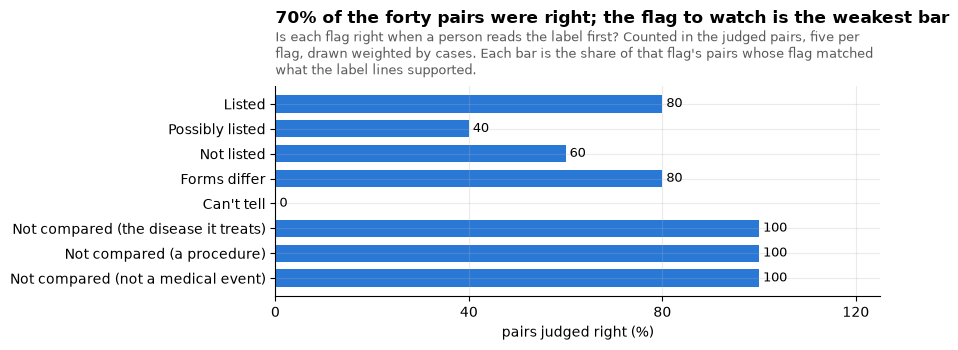

In [19]:
# The judged file: beside the notebook, or where OPEN_ALTIO_HAND_CHECK points
HAND = Path(os.environ.get("OPEN_ALTIO_HAND_CHECK", "10_label_flags.hand_check.judged.jsonl"))
if HAND.is_file():
    judged_rows = [json.loads(line) for line in HAND.read_text().splitlines() if line.strip()]
    verdict = {j["key"]: j for j in judged_rows}
else:
    verdict = {}
draw["verdict"] = draw.key.map(lambda k: verdict.get(k, {}).get("verdict"))
draw["right"] = [
    None if v_ is None else v_ == MEANS[o]
    for v_, o in zip(draw.verdict, draw.outcome_T, strict=True)
]
have = draw[draw.right.notna()].copy()
print(f"{len(have)} of {len(draw)} drawn pairs judged ({HAND})")
rows = []
for outcome in STRATA:
    part = have[have.outcome_T == outcome]
    k, total = int(part.right.sum()), len(part)
    lo, hi = wilson(k, total)
    wk = int(part.cases_T[part.right.astype(bool)].sum()) if total else 0
    wt = int(part.cases_T.sum()) if total else 0
    rows.append(
        {
            "flag": say(outcome),
            "right": f"{k} of {total}",
            "95% interval": f"{lo:.0f} to {hi:.0f}%" if total else "",
            "cases right": f"{wk:,} of {wt:,}",
        }
    )
result = pd.DataFrame(rows)
display(result)
if len(have):
    k, total = int(have.right.sum()), len(have)
    lo, hi = wilson(k, total)
    wk = int(have.cases_T[have.right.astype(bool)].sum())
    wt = int(have.cases_T.sum())
    print(
        f"overall {k} of {total} right ({100 * k / total:.1f}%, 95% interval {lo:.0f} to {hi:.0f}%); "
        f"weighted by cases {wk:,} of {wt:,} = {100 * wk / wt:.1f}%"
    )
    display(
        have[~have.right.astype(bool)][["rxnorm_name_T", "pt", "outcome_T", "verdict", "cases_T"]]
        .assign(flag=lambda d: d.outcome_T.map(say))
        .drop(columns="outcome_T")
    )
    fig, ax = plt.subplots(figsize=(9, 3.6))
    shares = [
        100 * float(r_.split(" of ")[0]) / max(float(r_.split(" of ")[1]), 1)
        for r_ in result["right"]
    ]
    bars(ax, result.flag.tolist(), shares, SERIES[0], "pairs judged right (%)", fmt="{:.0f}")
    title(
        ax,
        f"{100 * k / total:.0f}% of the forty pairs were right; the flag to watch is the weakest bar",
        "Counted in the judged pairs, five per flag, drawn weighted by cases. Each bar is the share "
        "of that flag's pairs whose flag matched what the label lines supported.",
        "Is each flag right when a person reads the label first?",
    )
    plt.tight_layout()
    plt.show()

**What section 6 shows.** The judgement for this draw is not in yet: the cells above draw the forty pairs and write the todo file, and report the result as soon as the judged file is beside the notebook.
- **Hand check per flag.** *Shows:* each row is one flag, five pairs judged blind against the label lines, with a 95% interval (Wilson) and the cases right out of the cases drawn. *Point:* it measures each flag's precision on the reports people meet, not on all pairs; five pairs per flag is a small sample, so the intervals are wide and the table is for finding the weak flag, not for ranking close ones. *So what:* a flag whose interval sits well below the others is the next rule to look at; every wrong pair is listed with the verdict and its cause.

## 7 · How accurate are the flags? The evidence notebooks

Three evidence notebooks (in the walks folder of the maintainers, `walk10-acc-literal`, `walk10-acc-impact`, `walk10-acc-rules`, each with its judged draws) tested a hypothesis each on the release before these rules; a draw is judged blind by a model, the interval is Wilson 95%, and "right" excludes borderline. A fourth, a blind re-judge of the draws with the flag removed (`walk10-acc-rejudge`), follows the table. Their results in plain words:

**Literal: reactions written word for word in the label, and false Listed.**
- A label that prints the reaction's name as part of a longer phrase rarely "states" it: of 40 hits drawn by cases, 7 (18%, interval 9 to 32%) stated the reaction as the drug's, 18 a more specific form (back pain for pain). The biggest "miss" is a rule working. Hyphen equivalence was tested (14 of 20 right, 70%) and **not** adopted.
- Is Listed ever false? 60 Listed pairs drawn by cases, deciding sentence read in full: 55 true, 4 false (7%, interval 3 to 16%), 1 unclear. A screen for cues (negation, patient group, other drug, placebo) found 12.9% of single-line Listed pairs; 5 of 20 drawn were false (25%), about 1.3% of Listed in all.
- The kept-off side hides more than the Listed side lies; no label failed as a whole in a way a rule could fix.

**Impact: whole-label failures, most seen flags, sibling drugs.**
- 2,493 labels read; 26 hold no safety text at all, and the 58 outlier labels carry 0.28% of case uses. The one true misread was a safety section that is only its heading (nine labels, mefloquine among them): kept to fix after launch, and a label with no safety text should read Not compared, not Not listed.
- The 100 most seen Not listed pairs (4.0% of case uses): 50 of 100 the label really is silent, 7 state it (5.9% of uses), 43 name a near term (40% of uses), mostly catch-all words; both flags sit in the Unexpected only view, so the cost is small. Of the 50 most seen Possibly listed pairs, 26 fit, 16 state it, 8 name nothing close.
- Sibling drugs (same ATC group) are not a misread detector: 14 of 20 were real label differences.

**Rules: nine candidate rules, a blind draw each (the table of results).**

| rule | moved | right | kept? |
|---|---|---|---|
| Drug hypersensitivity = Hypersensitivity | 4,764 pairs | 20 of 20 | yes |
| Peripheral swelling = Oedema peripheral | 1,253 pairs | 20 of 20 | yes |
| Drug dependence = Dependence | 465 pairs | 20 of 20 | yes |
| Liver function test abnormal = Transaminases increased | 586 pairs | 20 of 20 | yes |
| Breast cancer female = Breast cancer, Drug withdrawal syndrome = its twin, Blood glucose increased = Hyperglycaemia | 1,100 pairs | 59 of 60 across the seven pairs | yes |
| Anaphylactic shock = Anaphylactic reaction | 1,832 pairs | 20 of 20 | no: a more severe form is unexpected (ICH) |
| Abnormal weight gain, Asthenia = Fatigue, Hepatic function abnormal | 294 to 1,654 pairs | 18 of 20, 0 of 20, 0 of 20 | no |
| Seven coarse catch-all groups off the catch-all list | 67,542 pairs | 29 of 30 | yes |
| Ten close groups to Possibly listed | 23,396 pairs | 28 of 30; 16 of 20 on a fresh seed | yes, but the validation draw was lower |
| Opposite direction only to Not listed | 5,837 pairs | 30 of 30; 19 of 20 | yes |
| Unread negation (broad / Death and Confusional state), patient-context lines | 377 / 75 / 518 pairs | 27 of 30 / 12 of 12 / 29 of 30 | patient-context and the two named terms yes; broad negation no |
| "Nervous" heading read as a term | 156 pairs | 29 of 30 | yes |
| Device expulsion, drug resistance, vaccination failure compared on the exact term | 3,526 pairs | 44 of 50 | yes (exact term, not group link) |
| Product used for unknown indication to Not a medical event | 980 pairs | 20 of 20 | yes |
| Footnote marks stripped | 63 pairs | 14 of 15 | no, too small |

**The blind re-judge** (`walk10-acc-rejudge`: a second reader saw only the drug, the reaction as reported and the label lines, no flag, rule or earlier verdict; 490 items, 91% agreement with the first reader, kappa 0.69). Against the same bars (19 of 20 for rules that move to Listed or Not a medical event, above 50% for the others), the first reading held for: Drug hypersensitivity 20 of 20, Anaphylactic shock 20 of 20, Drug dependence 20 of 20, Product used for unknown indication 20 of 20, seven coarse groups 26 of 30, opposite direction 30 of 30, "Nervous" heading 27 of 30, patient-context lines 25 of 30, hypersensitivity, dependence and withdrawal together 38 of 40. It **did not hold** for: the ten close groups to Possibly listed (13 of 30, 43%, first reading 93%), the three twin pairs to Listed (14 of 20, 70%; all six misses are blood glucose, whose hyperglycaemia line the second reader could not see), Liver function test abnormal (16 of 20, 80%), and, as before, Asthenia and Hepatic function abnormal (0 of 20) and Abnormal weight gain (18 of 20). These stay provisional: the ten close groups, the glucose twin and the liver function twin go back to the walk with the lines the second reader missed, before they are relied on.

Caveats the notebooks state: the draws are uniform over pairs, not weighted by cases (section 6 is the weighted one); some todo files showed the flag, so the **blind re-judge** repeats them without it; pairs read on several labels were not moved by the rule tests.

In [20]:
# The blind re-judge, when it has been written; the evidence folder of the maintainers
ACC = Path(os.environ.get("OPEN_ALTIO_ACCURACY", Path.home() / "Documents/faers/walks"))
rejudge = ACC / "walk10-acc-rejudge.md"
print(rejudge.read_text() if rejudge.is_file() else "The blind re-judge is not written yet.")

# Accuracy: blind second reading of the rule draws
Second reader claude-sonnet-5-5 saw only drug, reaction as reported and label lines (blind copy, seeded-hash order, no flag, rule or earlier verdict); 490 items, 46 disagree with the first reader (91% agreement, kappa 0.69 over all items).
Right = a rule to Listed needs "states it", to Possibly listed "close", to Not listed or Not a medical event "not stated". Bar: 19 of 20 for rules to Listed or Not a medical event, above 50% for the others. Mine = my right count (Wilson 95%); first = first reader precision (right count).

| rule | n | mine right (95%) | first | agree, kappa | vs bar |
|---|---|---|---|---|---|
| a1 Drug hypersensitivity | 20 | 20 (84-100%) | 100% (20) | 20/20, k=na | ok |
| a2 Peripheral swelling | 20 | 19 (76-99%) | 100% (20) | 19/20, k=0.00 | ok |
| a3 Abnormal weight gain | 20 | 18 (70-97%) | 90% (18) | 20/20, k=1.00 | BELOW 19 of 20 |
| a4 Anaphylactic shock | 20 | 20 (84-100%) | 100% (20) | 20/20, k=na | ok |
| 

**What section 7 shows**, one item per evidence notebook.

- **Literal.** *Shows:* a word-for-word hit in a label is the drug's statement of the reaction in 18% of cases drawn (62% if a more specific form counts); Listed is false in 7% (interval 3 to 16%). *Point:* the fear that Listed is often false does not hold; the fear that a rule hides reactions does, mildly. *So what:* no new Listed rule from word-for-word hits; hyphen equivalence stays out.
- **Impact.** *Shows:* whole labels are read; the 58 outliers are short over-the-counter labels, gases and trace elements, and the most seen flags are rightly silent or Possibly listed about half the time. *Point:* a failing label is rare; the flags that matter most are mostly right. *So what:* the heading-only section fix and "no safety text reads Not compared" are after-launch fixes.
- **Rules.** *Shows:* the table above, one row per candidate rule. *Point:* a rule is kept only if it stays right where it takes a reaction out of the Unexpected only view (19 of 20 or better) or beats today's flag where it brings one in. *So what:* the rules kept are the rows kept above, each built as its own change.
- **Blind re-judge.** *Shows:* the draws re-judged with the flag removed: most rules hold, the ten close groups (43%), the glucose twin and the liver function twin do not reach their bars. *Point:* it removes the doubt that seeing the flag steered the first judgement. *So what:* those three go back to the walk before they are relied on.

## What this notebook asks

For the walk, the rules this notebook backs (each change to a rule is its own reviewed change with its evidence), in plain words:

1. **The fates and the join** (`rules/label-flags.md`): suspect records PS and SS, a person's rules can add I and C; trial products get no flag; a record with no RxNorm code, or whose code names another drug, shows Not compared (no label found).
2. **Which labels a record is read on** (`rules/label-choice.md`, `rules/drug-route.md`): its own form's label when known, its candidates' labels when each has one, every label otherwise, and Forms differ only when the labels disagree on expectedness; a combination is also read on each ingredient's own label (`rules/label-own-ingredients.md`).
3. **The flags and their order** (`rules/label-flags.md`, `rules/explorer-label-words.md`): expected, unexpected and set aside as above, in the words the screens use.

**Decided after this notebook's review:**
- The disease it treats is set aside only when the indications line names the disease the drug is given for; denials, intolerance, causes and "has not been shown to" set nothing aside (`rules/label-treated-disease.md`).
- Therapy interrupted, Therapy cessation and Therapy change are Not a medical event, no longer a procedure (`rules/label-not-a-medical-event.md`).
- Table rows that do not line up stay with the person review; no safe rule exists (`rules/label-table-rows.md`, `rules/label-review.md`).
- BIOVITRUM counts as Sobi from 2015Q4 (about 15,000 cases); the older AERS "BIOVITRUM AB." stays apart (`rules/company-names.md`).
- The package from the accuracy notebooks: seven same-meaning pairs read as Listed, seven coarse catch-all groups off the catch-all list, ten close groups to Possibly listed, opposite direction only to Not listed, unread negation of Death and Confusional state and patient-context lines not stated, the "Nervous" heading no term, exact-term comparison for device expulsion, drug resistance and vaccination failure, and Product used for unknown indication to Not a medical event (`rules/label-dictionary.md`, `rules/label-groups.md`, `rules/label-negation.md`, `rules/label-population.md`, `rules/label-not-a-medical-event.md`).
- Dropped: Anaphylactic shock as Listed on anaphylactic reaction, abnormal weight gain, hyphen equivalence, asthenia and fatigue, hepatic function, footnote marks.
- Open label questions: wording, naming and version link settled; underlines after launch, drawn first; old labels such as Avandia's are accepted as the only version DailyMed holds, with the date shown.

**Provisional fixes still to be shown fix by fix after launch**, each with a before and after on the final release and one example, before each is kept or undone: the package above as one fix per rule; the heading-only safety section and "no safety text reads Not compared"; the indication as a hint at the form (section 4); the person-review screen grouped by label; the drug-abuse-and-dependence section; originator brands without a DailyMed mapping (Rifadin, Altace); carrying reviewed answers across MedDRA versions; a Label column on All cases; a daily re-upload of the label tables.

**Found by the run and the hand check, for the owners of the steps before this one:** DailyMed holds no label for palivizumab (a search on 19 October 2026 gives 0 results), so its records stay Not compared (no label found); drug names and RxNorm codes name another drug for 5,389 records (bevacizumab as simvastatin, pantoprazole as omeprazole), which the flags no longer carry over.